In [1]:
%load_ext autoreload

%autoreload 2

In [2]:
import pandas as pd

pd.options.display.max_rows = 100
# pd.set_option('display.max_colwidth', None)

In [4]:
import src.core.file_manager as fm

In [5]:
path_dir = fm.filename_from_data_dir(f'embeddings/glove/text_emb_patient_with_word_embeddings.json')

df = fm.read_json_of_dir(
    path_dir,
    lines=True
)

df.head()

,txt,embeddings,tokens,word_embeddings
0,Tô muito nervosa Marcela com tudo isso,"[[0.08082773, -0.035568573, -0.048247125, 0.06...","[Tô, muito, nervosa, Marcela, com, tudo, isso]","[[0.14694000000000002, -0.5241800000000001, -0..."
1,O meu problema é psicológico nem dormi es...,"[[0.14869732, -0.14268143, -0.074482225, 0.045...","[O, meu, problema, é, psicológico, nem, dormi,...","[[-0.0018331999999999999, -0.3367, -0.13084, 0..."
2,Com muito medo,"[[0.07444667, -0.04100433, -0.39161667, 0.1238...","[Com, muito, medo]","[[0.039064, 0.34595000000000004, 0.11547, -0.4..."
3,Sim,"[[-0.20862000000000003, -0.27035000000000003, ...",[Sim],"[[-0.20862000000000003, -0.27035000000000003, ..."
4,A 3 meses atrás quando o meu esposo faleceu,"[[0.14331742, -0.17443344, -0.15340744, 0.0757...","[A, 3, meses, atrás, quando, o, meu, esposo, f...","[[-0.29712000000000005, 0.094049, -0.096662, -..."


In [5]:
index = 130
df.loc[index:index+10]

,txt,embeddings,tokens,word_embeddings
130,Somente isso mesmo.,"[[0.034420000000000006, -0.15973501, 0.08075, ...","[Somente, isso, mesmo, .]","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
131,Estou sentindo um pouco de falta de ar,"[[0.09137375, -0.12122875, -0.18246374, -0.246...","[Estou, sentindo, um, pouco, de, falta, de, ar]","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
132,E moro sozinha,"[[-0.13428666, 0.26853666, -0.31113002, -0.017...","[E, moro, sozinha]","[[-0.7428300000000001, 0.3709, -0.67932, 0.073..."
133,Só falta de ar,"[[0.17791499, -0.36975247, -0.3360375, -0.1834...","[Só, falta, de, ar]","[[0.52466, -0.5696500000000001, -0.66923000000..."
134,Repouso,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",[Repouso],"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
135,Não. Só o coração acelerado,"[[0.11009597, -0.29098335000000003, -0.3479000...","[Não, ., Só, o, coração, acelerado]","[[0.064869, -0.38784, -0.59582, -0.097811, -0...."
136,Nao,"[[0.03382, 0.24322000000000002, -0.36404000000...",[Nao],"[[0.03382, 0.24322000000000002, -0.36404000000..."
137,Até agora não coloquei o termômetro agora,"[[0.13105655, -0.20188856, -0.25139716, -0.030...","[Até, agora, não, coloquei, o, termômetro, agora]","[[0.14988, -0.46790000000000004, -0.29392, -0...."
138,Como tô chorando o nariz fica ruim. Pq tenho r...,"[[0.11267963, -0.10859645, -0.0558709060000000...","[Como, tô, chorando, o, nariz, fica, ruim, ., ...","[[0.17699, 0.29086, -0.39363000000000004, 0.09..."
139,E a falta de ar??,"[[-0.10290166, -0.07754316, -0.30895367, -0.26...","[E, a, falta, de, ar, ??]","[[-0.7428300000000001, 0.3709, -0.67932, 0.073..."


In [6]:
print([round(value, 4) for value in  df.loc[133]['embeddings'][0][-4:]])

[0.0111, -0.426, -0.2575, 0.1742]


In [7]:
token=0
size = 2

print([round(value, 4) for value in  df.loc[133]['embeddings'][token][:size]])
print([round(value, 4) for value in  df.loc[133]['embeddings'][token][-size:]])


[0.1779, -0.3698]
[-0.2575, 0.1742]


In [5]:
from src.clustering.pipeline_helper import PipelineHelper

[nltk_data] Downloading package stopwords to /home/valmir/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [6]:
pipeline = PipelineHelper(embedding_name='glove', actor='patient', k=99, sub_folder_k='k100/')

pipeline.run_clustering()

In [8]:
from googletrans import Translator

from src.clustering import wordcloud_helper as wh

translator = Translator()

df = pipeline.data_helper.df

def print_word_cloud_in_english_for_label(cluster_label):
    sentences = df[df['label'] == cluster_label]['txt'].to_numpy()

    translated_result = [
        translator.translate(sentence, src='pt_br', dest='en') for sentence in  sentences
    ]

    translated_sentences = [s.text for s in translated_result]

    wh.plot_word_cloud(" ".join(translated_sentences), name_file=cluster_label, stopwords=wh.ENGLISH_STOPWORDS)

In [13]:
df.head(2)

,txt,embeddings,annotated_txt,label,distance
0,Tô muito nervosa Marcela com tudo isso,"[[0.08082773, -0.035568573, -0.048247125, 0.06...",Tô muito nervosa Marcela com tudo isso,46,0.246451
1,O meu problema é psicológico nem dormi es...,"[[0.14869732, -0.14268143, -0.074482225, 0.045...",O meu problema é psicológico nem dormi es...,78,0.140348


In [16]:
df[df['label'] == 21].sort_values('distance')

,txt,embeddings,annotated_txt,label,distance
7789,Boa tarde. Amanhã faz 7 dias que estou com os...,"[[0.0027643843, -0.038495999999999996, -0.1817...",Boa tarde. Amanhã faz 7 dias que estou com os...,21,0.033151
20210,Sou o Franklins e desde a quarta-feira pela no...,"[[0.04084933, -0.12015669, -0.13316454, 0.0301...",Sou o Franklins e desde a quarta-feira pela no...,21,0.034101
9552,Olá! Bom dia! Gostaria de pedir orientações e...,"[[0.026734814000000003, -0.056778446, -0.13907...",Olá! Bom dia! Gostaria de pedir orientações e...,21,0.035519
23007,"Boa noite, já faz tres dias que comecei a toss...","[[0.0063751917, -0.13434663, -0.14494349, -0.0...","Boa noite, já faz tres dias que comecei a toss...",21,0.035561
23033,O médico disse que estar tudo bem com o pulmão...,"[[-0.042075966, -0.11987273400000001, -0.19136...",O médico disse que estar tudo bem com o pulmão...,21,0.037884
...,...,...,...,...,...
10311,q foi ano passado,"[[0.18722576, -0.36468872, -0.040090576, -0.01...",q foi ano passado,21,0.405294
23394,Muito obrigada q Jesus te proteja,"[[-0.055139992000000006, -0.13913767, -0.27955...",Muito obrigada q Jesus te proteja,21,0.434933
5316,"Era somente isso, obrigado, bom domingos","[[0.07872613, -0.23652589999999998, -0.1053798...","Era somente isso, obrigado, bom domingos",21,0.435111
5692,Bairro: Sede / Cidade: Quixeramobim,"[[0.35053229999999996, -0.23575999, -0.3457457...",Bairro: Sede / Cidade: Quixeramobim,21,0.459112


In [47]:
# df = pipeline.data_helper.df
# label 21
# df[df['txt'].str.lower().str.contains("perdi totalmente o apetite".lower())]['label', 'txt']].to_numpy()
df[df['txt'].str.lower().str.contains("e dor no peito mas".lower())][[ 'txt']].to_numpy()


# df[df['txt'].str.lower().str.contains("com vontade de vomitar".lower())][['label', 'txt']].to_numpy()

array([], shape=(0, 1), dtype=object)

In [ ]:
# 3 others
# 4 greeting
# 5 request_inform
# 10 / 26 inform_medicine
# 13  / 21/ 27/ 30 inform_symptoms

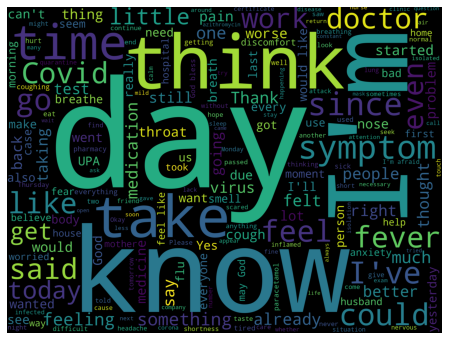

In [10]:
print_word_cloud_in_english_for_label(3)

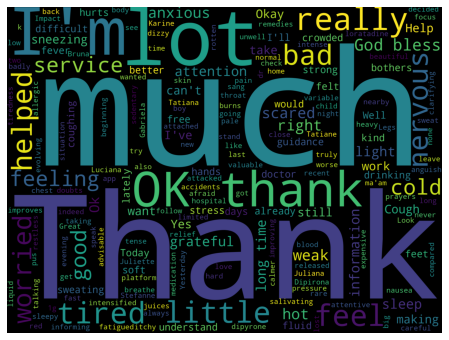

In [11]:
print_word_cloud_in_english_for_label(4)  #greeting

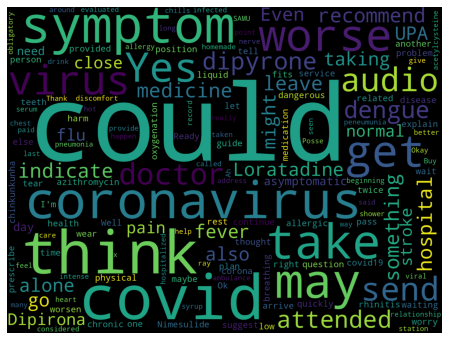

In [13]:
print_word_cloud_in_english_for_label(19) #request_inform

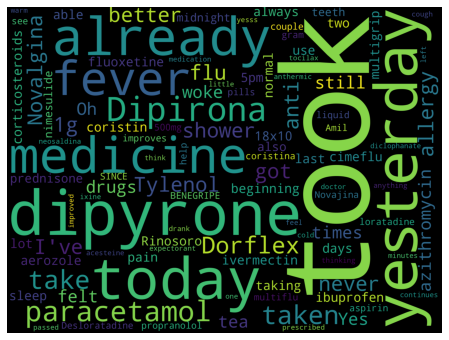

In [14]:
print_word_cloud_in_english_for_label(10) #inform_medicine

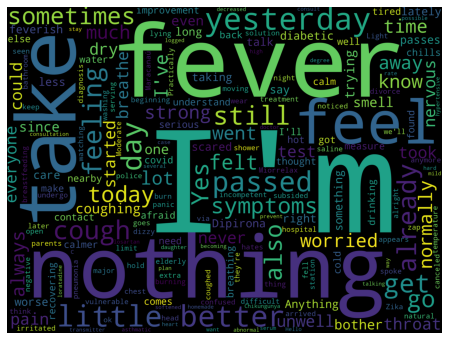

In [15]:
print_word_cloud_in_english_for_label(13) #inform_symptoms

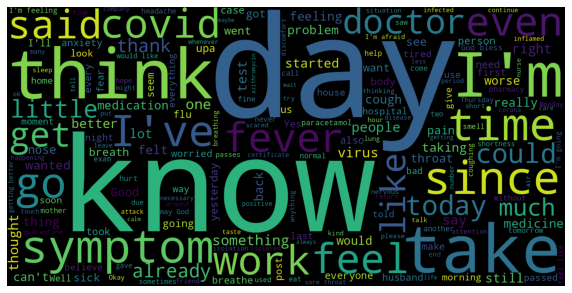

In [6]:
print_word_cloud_in_english_for_label(3)  #others

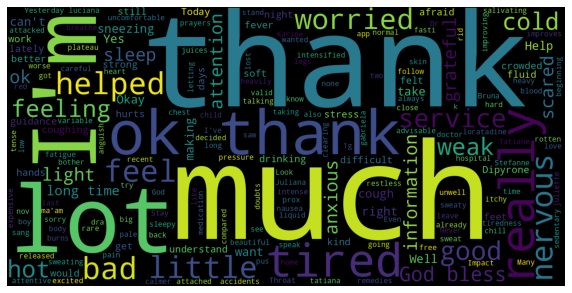

In [7]:
print_word_cloud_in_english_for_label(4)  #greeting

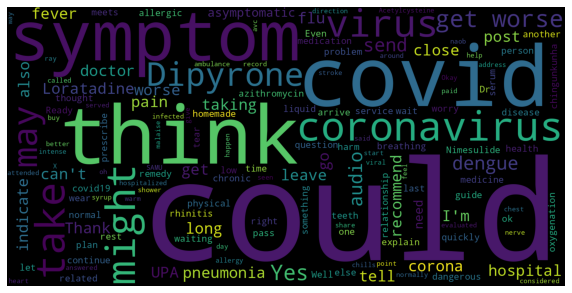

In [12]:
print_word_cloud_in_english_for_label(19) #request_inform

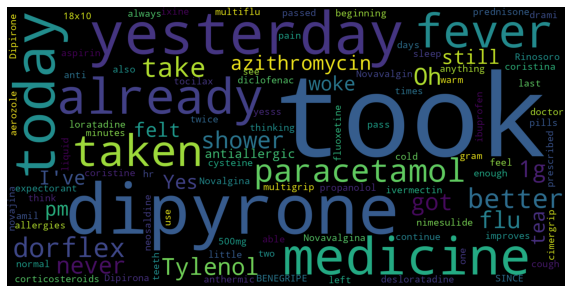

In [9]:
print_word_cloud_in_english_for_label(10) #inform_medicine

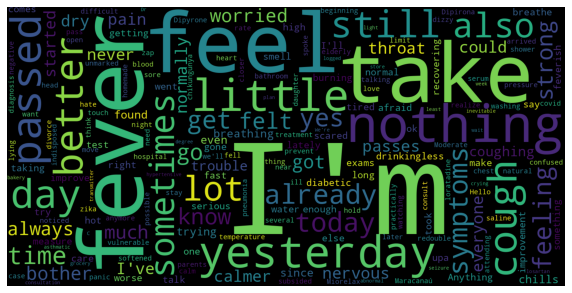

In [10]:
print_word_cloud_in_english_for_label(13) #inform_symptoms

In [8]:
pipeline.visualize_distance_distribution()

In [10]:
pipeline.data_helper.df

,txt,annotated_txt,embeddings,label,distance
0,Tô muito nervosa Marcela com tudo isso,Tô muito nervosa Marcela com tudo isso,"[[0.08082773, -0.035568573, -0.048247125, 0.06...",46,0.246451
1,O meu problema é psicológico nem dormi es...,O meu problema é psicológico nem dormi es...,"[[0.14869732, -0.14268143, -0.074482225, 0.045...",78,0.140348
2,Com muito medo,Com muito medo,"[[0.07444667, -0.04100433, -0.39161667, 0.1238...",88,0.189859
3,Sim,Sim,"[[-0.20862000000000003, -0.27035000000000003, ...",28,0.028385
4,A 3 meses atrás quando o meu esposo faleceu,A 3 meses atrás quando o meu esposo faleceu,"[[0.14331742, -0.17443344, -0.15340744, 0.0757...",78,0.253093
...,...,...,...,...,...
26749,"Ñ, só pressão baixa","Ñ, só pressão baixa","[[0.245006, -0.35744402000000003, -0.241274, 0...",44,0.270995
26750,Atende ?,Atende ?,"[[-0.041650000000000006, -0.10448, -0.02181149...",6,0.091449
26751,Vou ter q ir na Upa,Vou ter q ir na Upa,"[[0.17836982, -0.35779524, -0.0015172163000000...",63,0.256446
26752,Por que trabalho em mercantil,Por que trabalho em mercantil,"[[0.24479401, -0.21207538, -0.426164, -0.04268...",3,0.146575


In [25]:
pipeline.data_helper.df.head(1)

,txt,embeddings,annotated_txt,label,distance
0,Tô muito nervosa Marcela com tudo isso,"[[0.08082773, -0.035568573, -0.048247125, 0.06...",Tô muito nervosa Marcela com tudo isso,46,0.246451


In [11]:
# fig, df_plot = pipeline.visualize_tsne()
df_plot = pipeline.visualize_tsne()

df_plot.head()

Transforming embeddings
Creating chart....


,x,y,cluster,intent,text
6242,28.101503,-19.462398,62,greeting,Tá bom então
13375,23.734762,-24.224765,84,greeting,Oi Tamires!
2154,20.173654,-25.754275,60,greeting,Ok. Obrigada
13377,21.772754,-22.571022,52,greeting,Desculpe-me!
16509,19.385069,-25.045976,60,greeting,"Ok, obg"


In [70]:
import pandas as pd
from src.core import file_manager as fm
from src.clustering.tsne_helper import TsneHelper

df = fm.read_annotated_df_with_embeddings('glove', variation='k100')
print(df.isnull().sum())

df.head()

txt                0
annotated_txt      0
label              0
distance         776
intent             0
embeddings         0
dtype: int64


,txt,annotated_txt,label,distance,intent,embeddings
0,Tô muito nervosa Marcela com tudo isso,Tô muito nervosa Marcela com tudo isso,46,0.246451,inform_symptoms,"[[0.08082773, -0.035568573, -0.048247125, 0.06..."
1,O meu problema é psicológico nem dormi es...,O meu problema é psicológico nem dormi es...,78,0.140348,others,"[[0.14869732, -0.14268143, -0.074482225, 0.045..."
2,Com muito medo,Com muito medo,88,0.189859,inform_symptoms,"[[0.07444667, -0.04100433, -0.39161667, 0.1238..."
3,Sim,Sim,28,0.028385,others,"[[-0.20862000000000003, -0.27035000000000003, ..."
4,A 3 meses atrás quando o meu esposo faleceu,A 3 meses atrás quando o meu esposo faleceu,78,0.253093,others,"[[0.14331742, -0.17443344, -0.15340744, 0.0757..."


In [83]:
title_tsne = f'T-SNE algorithm: fast_kmeans model: Glove actor: Patient'
tsne_helper = TsneHelper(df, title_tsne)
fig, df_data = tsne_helper.build_tsne_chart()

fig.update_layout(
    height=800,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1
    ),
)

fig.update_layout(
    title={'font': {'size': 60}},  # Tamanho do título
    xaxis={'title': {'font': {'size': 48}}, 'tickfont': {'size': 36}},  # Tamanho dos títulos e ticks do eixo x
    yaxis={'title': {'font': {'size': 48}}, 'tickfont': {'size': 36}},  # Tamanho dos títulos e ticks do eixo y
    legend={'font': {'size': 48}}  # Tamanho da legenda
)

fig.update_traces(marker=dict(size=16))

fig.write_image('chart.png', width=2400, height=1800, scale=1)

Transforming embeddings
Creating chart....


In [85]:
import plotly.express as px

fig = px.scatter(
    df_data,
    x="x",
    y="y",
    color="intent",
    color_continuous_scale='Bluered_r',
    hover_data=['text', 'cluster', 'intent']
)

fig.update_layout(
    height=800,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1
    ),
)

fig.update_layout(
    title={'font': {'size': 60}},  # Tamanho do título
    xaxis={'title': {'font': {'size': 48}}, 'tickfont': {'size': 36}},  # Tamanho dos títulos e ticks do eixo x
    yaxis={'title': {'font': {'size': 48}}, 'tickfont': {'size': 36}},  # Tamanho dos títulos e ticks do eixo y
    legend={'font': {'size': 48}}  # Tamanho da legenda
)

fig.update_traces(marker=dict(size=16))

fig.write_image('chart.png', width=2400, height=1800, scale=1)

fig.show()

In [86]:
import json
import pandas as pd
import matplotlib.pyplot as plt

file_name = fm.filename_from_data_dir('output/patient/without_others_intent/k100_without_sentences_higher_than_median/glove/rasa/results/intent_report.json')
# Carregar o arquivo intent_report.json

with open(file_name) as f:
    data = json.load(f)

# Preparar os dados para o histograma
intents = []
confidences = []

for intent, metrics in data.items():
    if intent not in ["accuracy", "macro avg", "weighted avg"]:
        confused_with = metrics["confused_with"]
        for confused_intent, count in confused_with.items():
            intents.append(f"{intent} -> {confused_intent}")
            confidences.append(count)

# Criar um DataFrame com os dados
df = pd.DataFrame({
    'Intents': intents,
    'Confidences': confidences
})

# Ordenar o DataFrame pelos valores de confiança
df = df.sort_values(by='Confidences', ascending=False)

# Plotar o histograma
plt.figure(figsize=(15, 7))
plt.barh(df['Intents'], df['Confidences'], color='skyblue')
plt.xlabel('Número de Confusões')
plt.ylabel('Confusão de Intenções')
plt.title('Confusões de Intenções Previstos pelo Modelo')
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: '/home/valmir/dev/python/intent_classifier/data/patient/without_others_intent/k100_without_sentences_higher_than_median/glove/rasa/results/intent_report.json'

In [74]:
df_data

,x,y,cluster,intent,text
6238,-11.491949,13.702271,04,greeting,Esses dias estava muito fraco no aplicativo
19067,-29.290620,11.955047,61,greeting,Certo....
20138,-28.108655,17.202319,52,greeting,Cansaço físico!
19064,-7.181936,35.319926,67,greeting,Pela noite
6876,-30.483918,23.606492,08,greeting,Bom dia Fabiana
...,...,...,...,...,...
17869,-4.117797,-18.242419,98,request_inform,Eu estou tomando loratadina 24 h de diferença
17871,-0.841971,12.543649,05,request_inform,Tenho um xarope chamado torante posso tomar tmb?
17875,-14.465380,-3.273259,93,request_inform,Na situacao q estamos?
10339,-6.658387,15.816601,19,request_inform,Tô tomando so Dipirona Pode tomar ?


In [4]:
df_data, fig = pipeline.visualize_tsne()

fig.show()

Transforming embeddings
Creating chart....


In [11]:
import plotly.express as px

df_data

,x,y,cluster,text
0,-22.872003,17.307412,00,Idade: 72
1,-11.629504,25.623908,00,Exercícios
2,-9.783436,23.471394,00,Ontem
3,-13.087933,24.241375,00,Síndrome nefrótica
4,-10.885653,26.966014,00,Outra coisa
...,...,...,...,...
26749,-10.552610,-13.722343,98,Eu estou tomando loratadina 24 h de diferença
26750,-11.254882,4.214319,98,So se eu tiver me movimentando
26751,-10.592911,4.992023,98,Ou eu troco?
26752,5.366764,-4.406575,98,Vc recomenda que eu continue ?


In [18]:
df_intent = pd.read_csv(fm.filename_from_data_dir('output/patient/k100/glove/annotated_sentences.csv'))
df_intent.head(2)

,txt,annotated_txt,label,distance,intent
0,Tô muito nervosa Marcela com tudo isso,Tô muito nervosa Marcela com tudo isso,46,0.246451,inform_symptoms
1,O meu problema é psicológico nem dormi es...,O meu problema é psicológico nem dormi es...,78,0.140348,others


In [12]:
import random

In [13]:
def generate_random_color():
  r = random.randint(0, 254)
  g = random.randint(0, 254)
  b = random.randint(0, 254)
  
  return f"rgb({r}, {g}, {b})"

def make_colors(size):
  random.seed(42)
  colors = []
  for i in range(size):
    color = generate_random_color()
    
    while color in colors:
      color = generate_random_color()
    
    colors.append(color)
  
  return colors

In [14]:
len(df_data['cluster'].unique())

97

In [20]:
# n_colors = len(df_data['cluster'].unique())
n_colors = len(df_intent['intent'].unique())


# colors = px.colors.sample_colorscale("viridis", [n/(n_colors -1) for n in range(n_colors)])
colors = make_colors(n_colors)

fig = px.scatter(
  # df_data,
  df_intent,
  x="x",
  y="y",
  # color="cluster",
  color="intent",
  #color_continuous_scale='Bluered_r',
  color_discrete_sequence=colors,
  hover_data=['text', 'intent']
)

fig.update_layout(
  height=800,
  legend=dict(
      orientation="h",
      yanchor="bottom",
      y=1.02,
      xanchor="right",
      x=1
  ),
  font=dict(size=18)
)

ValueError: Value of 'hover_data_1' is not the name of a column in 'data_frame'. Expected one of ['x', 'y', 'cluster', 'text'] but received: intent

In [83]:
fig = px.scatter(
  df_data[df_data['cluster'] == '21'],
  x="x",
  y="y",
  color="cluster",
  #color_continuous_scale='Bluered_r',
  color_discrete_sequence=colors,
  hover_data=['text', 'cluster'],
  title="t-SNE Visualization for a cluster of Inform Symptoms Intention"
)

# fig.update_layout(
#   height=800,
#   legend=dict(
#       orientation="h",
#       yanchor="bottom",
#       y=1.02,
#       xanchor="right",
#       x=1
#   ),
#   font=dict(size=18)
# )
fig.update_layout(showlegend=False, font=dict(size=18), height=800)

Total of sentences is: 956 for the label: 0


['Obrigada' 'Brigadaa' 'Repouso' 'Sozinha' 'Arritmia' 'Tosse' 'Febril'
 '64 também' 'De 6 em 6 horas' 'Estou ciente' 'Tenho ansiedade'
 'Mexeu comigo' 'Correto' 'Obgda' 'Agradeço' 'Muitíssimo obrigada'
 'Somente' 'Umas 10' 'Dipirona' 'Amitriptilina']


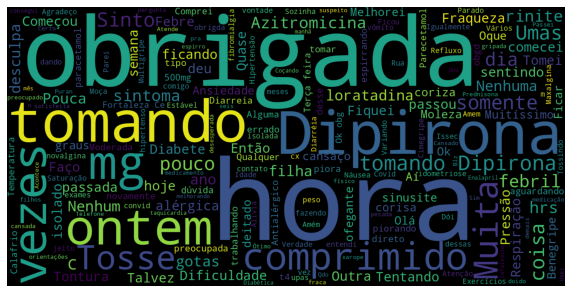





Total of sentences is: 700 for the label: 1


['São sutomos mesmo, por isso não tiro eles pra vir morar comigo, apenas faço adaptações pra que eles sintam se bem na casinha deles'
 'Hoje só tomei o antialérgico Alektos  Já vinha tomado ele desde antes do isolamento'
 'Até agora está tudo bem. Vou esperar mais uns dias e qualquer coisa dou um retorno aqui pra vocês!'
 'já faz 5 semanas'
 'Percebi que não posso fazer muito esforço ainda que fico muito ofegante'
 'Mas eu tbm não tinha feito esforço como fiz hj pela manhã'
 'Vieram fazer o teste na minha casa só'
 'Queria saber o que posso fazer pra alivia essa dor'
 'Os mesmo sintomas persistem,mas ele está conseguindo se alimentar bem até então'
 'Acho que swja leve'
 'Nao tem nenhuma outra coisa que posso fazer em casa'
 'Vou trabalhar, tenho horário para entrar e sem hora pra sair'
 'A mãe da minha amiga que alugou aqui pra mim'
 'Só até meio dia depois disso só se for na barraca'
 'Isso é o que tô precisando muito'
 'Acho que já c

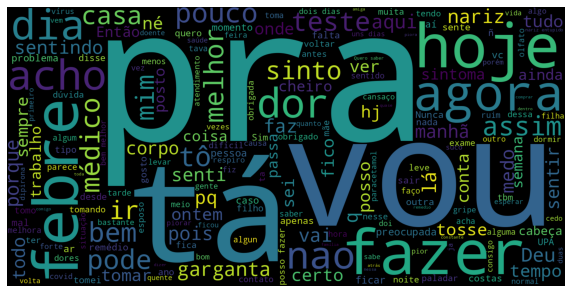





Total of sentences is: 145 for the label: 2


['Meu esposo já tem quase 60' 'Mas hj meu coração tá muito acelerado'
 'Meu corpo doi muito' 'Quando meu nariz entope sim' 'Meu filho'
 'Um médico amigo meu' 'Pode olhar meu prontuário'
 'Hoje termina meu afastamento' 'Podecser pq estou tossindo mto'
 'To mto nervosa moça' 'Meu nariz estava entupido'
 'Acho que meu olfato tá ruim' 'É meu sobrinho' 'Meu sobrinho' 'Fadiga'
 'Meu esposo está doente' 'Moro com meu marido' 'Meu marido'
 'Meu pai senti cansaço,febre só'
 'Acho estranho essa vermelhidão no meu tórax']


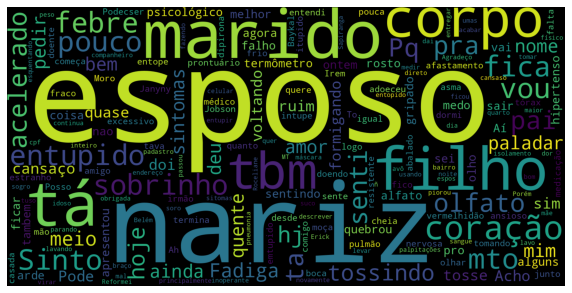





Total of sentences is: 890 for the label: 3


['Tem algum remédio  que a pessoa tome para se acalmar'
 'Estou orientando quanto o vírus por que a viúva é diabética'
 'Queria  a polícia pra dar uma orientação , possa ser que eles acreditem, pois já que não conhecem'
 'Diz que assim mesmo a vida! Uns nascendo outros morrendo'
 'Um pouco, acho que por conta da tosse'
 'Dor não sei se é nas costas a pressa que dá é na costela   Dificuldade na respiração    Falta de apetite  Tosse  Náuseas  Congestão nasal nariz entupido'
 'Como tô chorando o nariz fica ruim. Pq tenho renite' 'Que médico??'
 'Então digamos que tenho uma imunidade boa'
 'Mas dentro dessa situação, será que posso ser contraído o vírus?  Ou pode ser que eles tenham pegado uma virose, alguma hipótese?'
 'No momento não, já que essa minha amiga veio a 2 dias atrás, então melhor esperar um pouco mais pra ver se aparece alguns sintoma, correto?'
 'Desde segunda feira que não sinto cheiro'
 'Só fiquei mais nervosa por pensa que

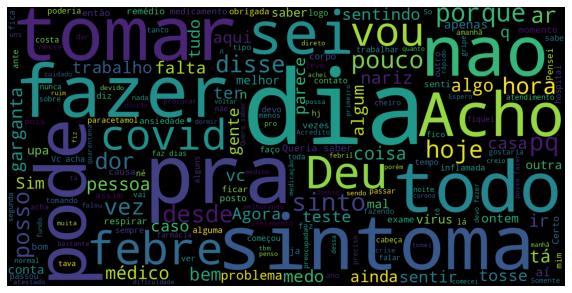





Total of sentences is: 246 for the label: 4


['Muito leve' 'muito obrigado' 'Muito' 'sinto muito medo'
 'pois doutora muito obrigada' 'Pois o hospital prox estão muito lotado'
 'Muito obrigada!!' 'Estou salivando muito' 'Muito obg'
 'Obrigada vc me ajudou muito' 'Nao, muito obrigado pelo seu tempo.'
 'Muito obrigado!' 'Estou muito preocupada' 'Suo muito'
 'Tenho tomado remdios caseiros e bebido muito liquido'
 'Ta ok muito obrigado' 'Ajudou muito' 'Muito obrigado' 'Muito obrigada.'
 'Agradeço muito']


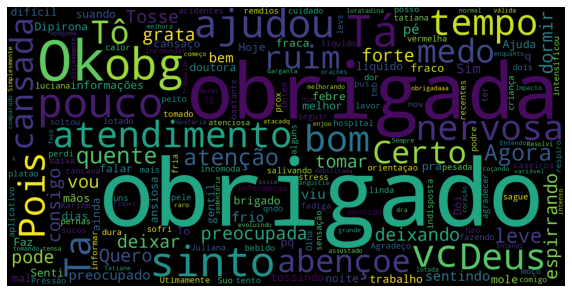





Total of sentences is: 175 for the label: 5


['Como posso melhorar' 'eu queria saber qual remédio posso tomar'
 'Comprei um Alegra na farmácia posso tomar?'
 'Então amanhã posso trabalhar normal' 'Posso tomar algum remédio'
 'Tenho esse remédio posso Tomar' 'Posso mandar uma foto do comprimido'
 'Que remédio pra gripe posso tomar' 'Posso   falar por audio'
 'E medicação posso tomar alguma' 'Posso tomar loratadina????'
 'Oq posso tomar em relação essa quentura'
 'qualquer coisa posso solicitar depois?'
 'Certo posso tomar o paracetamol agora?' 'Posso mandar áudio?'
 'Obrigado posso voltar a falar novamente' 'posso toma algum remedio'
 'posso tomar algun remédio' 'nao posso tomar remedio'
 'Posso tomar aerosol só com soro?']


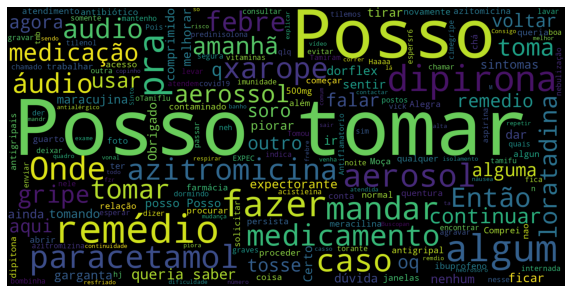





Total of sentences is: 226 for the label: 6


['Ou soro mesmo?' 'Nenhuma medicação ?' 'Em relação a febre?' 'Normal ?'
 'Obrg?' 'So embaixo do peito' 'Q faço?' 'Esses sucos sao indicados?'
 'Estou um O pouco acima do peso' 'Perda total do olfato e paladar.'
 'A do Jangurussu também tá atendendo?' 'Tem algum q vc possa me indicar?'
 'Alguma orientação?' 'Jussara?' 'Depois do banho to assim'
 'E esses sintoma dele é sintoma do covid?' 'Tô do mesmo jeito' 'então?'
 'So o q sinto' 'É normal?']


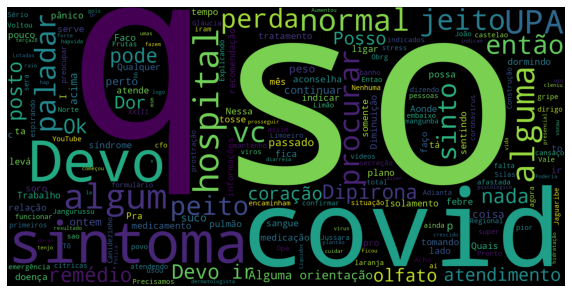





Total of sentences is: 345 for the label: 7


['Não' 'Não.' 'Não. Só o coração acelerado' 'As outras não' 'Não obrigada'
 'Nimesulida não' 'Não tenho' 'Não. Obrigada' 'Não. Obrigado' 'não'
 'Não não' 'Não,  obrigado' 'Não !' 'Não, ela é conservadora'
 'Não, obrigada'
 'Não  So refluxo laringite  Fendas cordas  vocais rinite  alerguca'
 'Na verdade eu me alimento , só não com muita regalia pq não tenho'
 'Não sei' 'Não sinto cheiro' 'Não tenho feito nenhuma atividade']


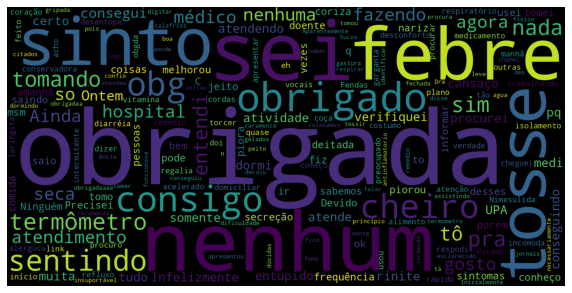





Total of sentences is: 154 for the label: 8


['Bom dia' 'Olá bom dia' 'Obg..bom dia' 'Ok obrg bom dia'
 'Só no primeiro dia' 'Durante o dia estava 35, 36' 'Bom dia.'
 'olá Amanda bom dia' 'e bom dia' 'oi bom dia'
 'Comecie senti no dia 30/04' 'Dia 30 medi minha saturação estava 90'
 'Hoje vai pro 6 dia' 'Ok tenha um bom dia'
 'Mas minja febre so durou 1 dia' 'Bom dia, Miriã' 'Somente 1 dia'
 'Bom dia Valeska.' 'Bom dia, eu estou melhor.' 'dia 27/4 fui a upa']


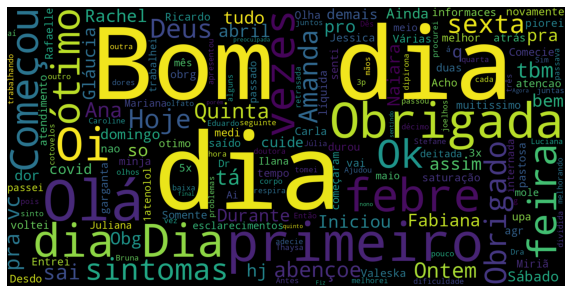





Total of sentences is: 414 for the label: 9


['Desde de ontem' 'De atendimento via whatsapp' 'De pronto atendimento'
 'Sintomas de covid' 'no começo senti 2 dias de febre'
 'tive 3 dias de diarréia' 'Sintomas de sinusite'
 'A possibilidade de ser Corona Vírus?' 'Gsotaria de orientação'
 'Me enquadro no grupo de     risco'
 'Comecei a sentir dificuldade de respirar' 'Sintomas de sibdrome gripal'
 'Fosfato de oseltsmivir' 'De fraqueza'
 'Estou de cama desde a segunda-feira' 'É a de tratamento'
 'Temperatura de 37,9° depois de 38,1°' 'Quando vi a temperatura de 38,1°'
 'Uso o remédio de pressão' 'Sim,hoje estou de folga.']


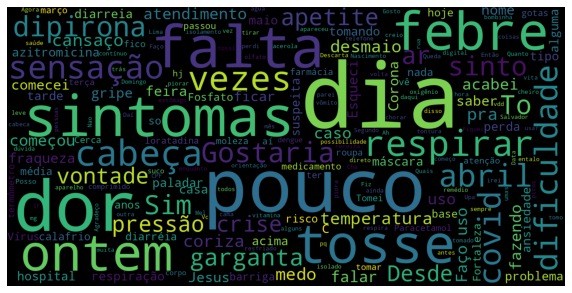





Total of sentences is: 100 for the label: 10


['Tomei Tylenol ontem' 'Hoje tomei a última azitromicina'
 'Por q ja tomei dorflex' 'Ai tomei dorfex' 'Ja tomei dorflex pra dor'
 'Sim tomei um cimergrip' 'Sempre tomei, estava 18x10' 'Tomei hoje também'
 'Tomei só remédio normais  Antigripais' 'Tomei hoje'
 'Tomei por conta própria' 'Já tomei paracetamol no inicio'
 'Só tomei dipirona' 'Hj não tomei dipirona' 'Tomei Novalgina 1g'
 'Tomei dois ivermectina ontem' 'Já tomei bastante Tylenol'
 'Tomei tylenou pra febre' 'Tomei um ibuprofeno' 'Já tomei fluoxetina']


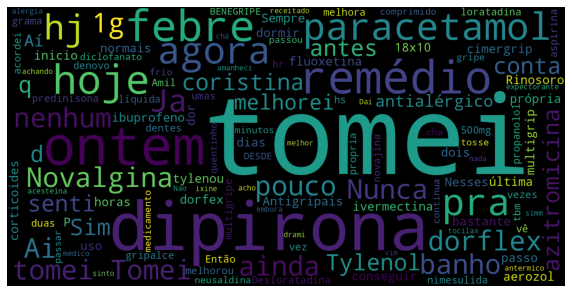





Total of sentences is: 114 for the label: 11


['Tá' 'Tá bem' 'Tá bem. Vou tentar!!' 'Nenhuma febre'
 'De subir escada,quando tá fazendo algo tá cansando rápido, tá suando'
 'Ela tá molinha tb' 'Tá vou ligar' 'Leve' 'Tá ok' 'Febre' 'Tontura leve'
 'Qual Upa tá  atendendo' 'Nenhuma apresentou febre'
 'Tá legal obrigada mesmo' 'Febre também'
 'Mas o nariz nem tá escorrendo e nem tá entupido' 'IPM'
 'Ele tá tomando quando a febre aparece' 'Tá bem! Muito obrigada'
 'Por hj tá otimo']


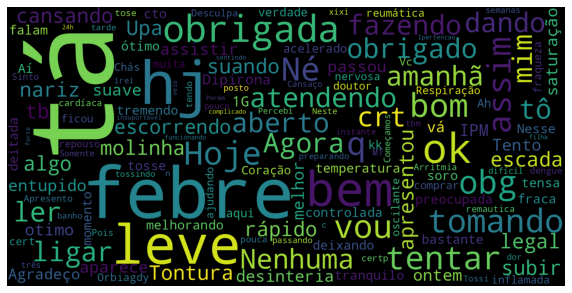





Total of sentences is: 51 for the label: 12


['Vc tb' 'Tbm' 'Vc acha' 'Tbm tenho tosse cheia'
 'Qualquer coisa chamo vcs' 'Sou hipertensa tbm' 'Obrigada vc também'
 'Pra vc tbm' 'Larguei 00:00' 'Tbm espero' 'Pk' 'Torse tbm' 'Vc tbm'
 '19:30 hrs' 'Estou tomando dipirona 6/6 hrs' 'Obg vc'
 'Vc acha melho bate um eletro' 'Diarreia tbm' 'Tbm 38' 'Pra falar tbm']


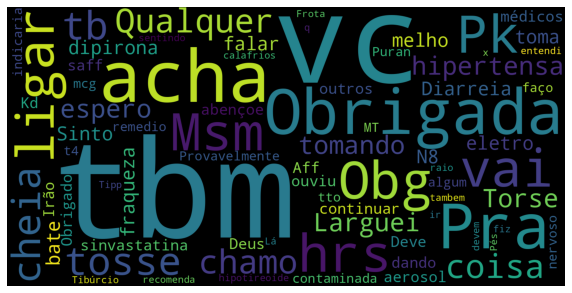





Total of sentences is: 247 for the label: 13


['Pasa a febre, mas demora bastante'
 'Aí um tosse as vezes mas nada tão forte'
 'Mas mesmo assim a gente fica confusa' 'Mas vou redobrar cuidados'
 'mas tbm deitado' 'mas estou no meu limite' 'Mas já estou melhor'
 'mas amamento.' 'Mas a febre diminuiu' 'Mas nao tenho febre ou tossi'
 'Mas Costa aimda' 'Mas então'
 'Qual hospital mas próxima poderia ir aqui no Maracanaú'
 'Mas tenho inperteçao sou diabético'
 'Mas pode serpor causa da febre tanbem' 'Mas estou muito assustado'
 'Aí ele toma banho, toma Dipirona mas demora pra passar'
 'Mas conheço minha temperatura' 'Mas conversamos depois ok'
 'Leve mas sim.']


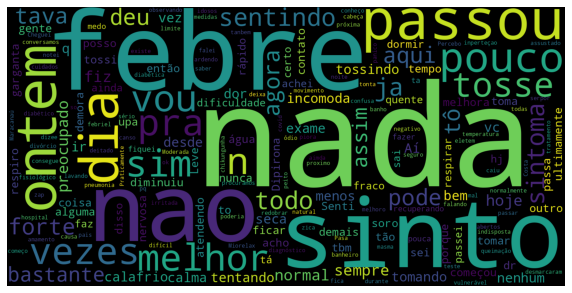





Total of sentences is: 342 for the label: 14


['Estamos abalados emocionalmente' '6/6 horas' 'Nunca'
 'Que desde sábado estão sentido' 'Já estamos sim' 'Tipo'
 'Desde semana passada' 'existe testes' 'estamos usando sempre'
 'Nunca consegui uma consulta aqui' 'Nunca ouvi falar'
 'Venho alternando estes sinomas desde sábado' 'Desde quara'
 'Sentir pouco' 'Esta ocilando' 'Para evitar aglomerações'
 'Tenho aqui dramin' 'Estamos'
 'Mas como tenho quase 90kg fico pensando se não seria apenas pelo sedentarismo'
 'Nunca fiz exames']


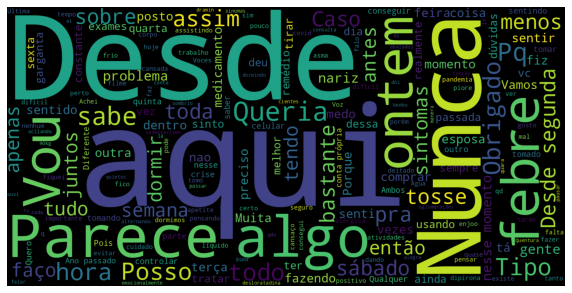





Total of sentences is: 357 for the label: 15


['Estou sentindo um pouco de falta de ar' 'Só falta de ar'
 'Nunca fiquei com falta de ar'
 'O coração acelerado desde ontem. Mas a falta de ar hj'
 'E essa falta de ar? Tem algum exercício'
 'Ainda sinto um pouco de falta de ar e taquicardia' 'Falta de ar'
 'Falta de ar, dor nos peitos' 'falta de ânimo'
 'Senti um pouco de falta de ar pela manhã' 'Falta de ar mesmo deitada'
 'E nao teve falta de ar' 'Só falta de ar e as vezes tontura'
 'Estou tossindo bastante, mas não sinto falta de ar'
 'Mas não estou c falta de ar ou tosse ou espirrando as vezes acontece mas raramente'
 'E não tenho falta de ar'
 'Tive um pouco de falta de ar   na noite passada ,mais foi leve'
 'Falta de ar moderada' 'Estou me sentindo um pouco de falta de ar'
 'Falta de ar leve']


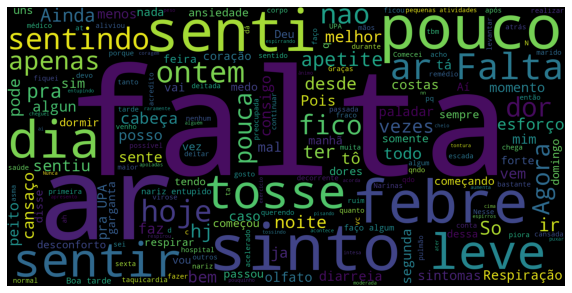





Total of sentences is: 124 for the label: 16


['Nao' 'Nao tenho febre' 'Nao obrigada' 'Nao estou me sentido bem'
 'Nao fui' 'Estou tentando nao ir' 'Nao estou cim febre'
 'Nao percebi ainda' 'Nao sei se twm alguma  relação'
 'Pegar nao mas passei perti' 'Nao tenho termmetro' 'Nao mexem'
 'Doutora nao tenho febre aparentemente' 'Nao sai nem fui a hospital'
 'Nao estou sentindo tontura' 'Ainda nao' 'Nao so isso' 'nao'
 'Nao fiz exame' 'Nao muito']


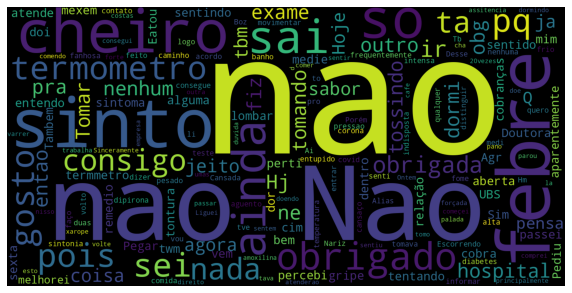





Total of sentences is: 92 for the label: 17


['ela passou uns dias sentindo mal estar intenso mas ja passou'
 'Passo mal no banheiro' 'Desde terça feira venho me sentindo mal'
 'Febre moderada,tosse e mal estar' 'Está com mal estar! (Corpo mole)'
 'Mal estar' 'O mal estar ébem incomodo' 'Só um mal estar'
 'Sexta-feira passei mal pensei que ia ter um infarto'
 'Faz mal tomar antialérgico' 'Só estou com um mal estar'
 'Com mal estar e minhas narinas um pouco dilatadas'
 'Faz muito mal tomar esses remédios controlados,m'
 'Moça, é um mal estar no estômago'
 'Eu ando tendo um mal estar enorme no estômago'
 'Tou com mal estar tive febre so pela manha' 'Estou passando mal'
 'porém me preocupei com esse mal estar' 'Sintino mal está'
 'Mal estar com umas dores leves nas costas']


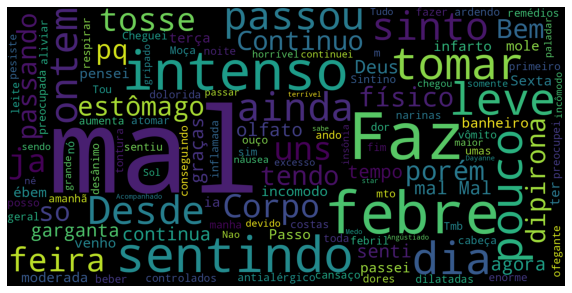





Total of sentences is: 150 for the label: 19


['Pode indicar?' 'Pode ser coronavirus?' 'Pode ser isso?'
 'A senhora acha que pode ser covid' 'Nimesulida pode?!'
 'Pode me indicar  hospital que atenda pelo meu plano'
 'Pode tomar algum remedio' 'Pode deixar' 'Pronto! Pode deixar'
 'Mas pode ser né' 'Pode ser desgaste físico?'
 'Ele pode poderia azitromicina ?' 'Pode' 'Pode ser áudio?'
 'Pode ser outra coisa?' 'Pode ser'
 'Essas dores nao pode estar relacionado a isso??'
 'Isso pode ser um dos sintomas da covid?' 'Sim pode ser'
 'Pode ser algum problema de saúde']


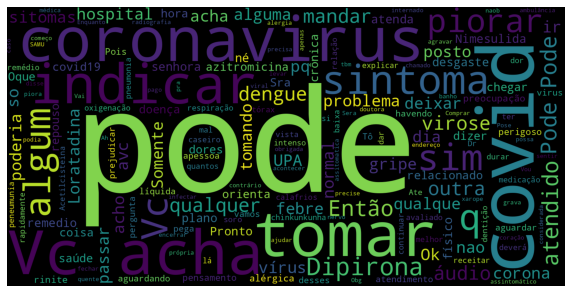





Total of sentences is: 327 for the label: 20


['Tô saindo procurar recursos' 'Nessa época' 'Vou procurar' 'Obg'
 'aos pequenos esforços' 'tive até ontem' 'Inspiração profunda' 'Sábado'
 'após fazer algum esforço físico' 'ontem também tava' 'Tomara' 'Quarta'
 'Continua' 'Ontem tive febre porem baixa' 'Vou dormir'
 'Vou tentar dormir' 'Deu' 'Obg moça' 'Nariz entupido etc'
 'Trabalho numa padaria']


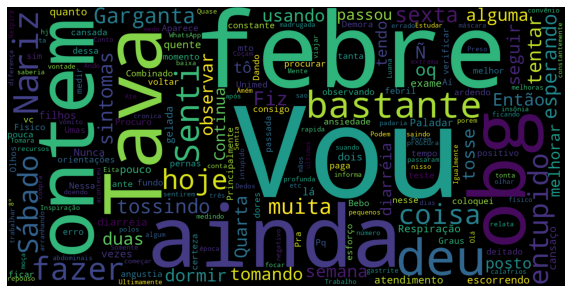





Total of sentences is: 1187 for the label: 21


['Eu preciso de um psicólogo pra eles O luto é patológico e o temor do Corona está acabando com eles'
 'Estou a 03 dias com febre e tosse seca, muitas dores nas costas'
 'Sinto como se o nariz tivesse entupido. Fui dar aula on-line hoje de manhã e me senti ofegante ao falar'
 'Ontem me senti melhor com Tylenol. Mas, o efeito não durou muito'
 '2, na verdade. Não tomei hoje ainda'
 'Estou sozinha em casa. Estou estudando muito pouco.. treino pelo menos umas 3x na semana.'
 'Bom, eu não tenho certeza se estive realmente em contato com pessoas infectadas, mas veio uma amiga minha e ela relatou que o irmão dela (21 anos) e o pai (acima de 30 anos), estavam sentindo febre a exatas duas semanas, febre direto.  E essa minha amiga não apresentou sintomas, pelo menos não no dia que ela veio.  Será que por mais que eu tenha "entrado" em contato eu deveria fazer um teste pra saber?!'
 'Mas muito obrigado, e agradeço também pelo trabalho que você

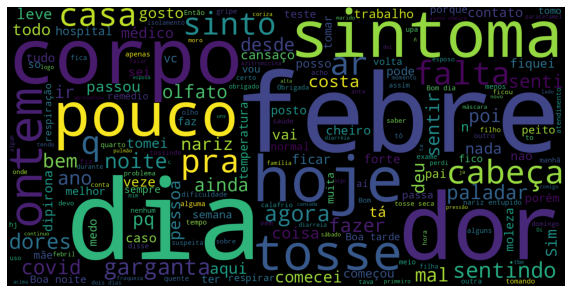





Total of sentences is: 154 for the label: 23


['No sábado passado.' 'No nariz uso Neosoro'
 'Comecei com espirro no dia 25' 'A gente vai no hapvida'
 'pq tenho câncer no estomago' 'No momento so'
 'Sentindo também uma pressão no peito' 'No peito'
 'Pressão no peito constante' 'No hospital acabo q tenho'
 'Está no oxigênio,tomando antibiótico' 'Quinta feira no final do dia'
 'no hospital  otoclinica' 'Mas no caso estou indo trabalhar normal'
 'Estou no 4 dia' '38 no começo' 'No dia 30/04' 'So moleza no corpo'
 'No momento' 'No caso estou com receio em ir no upa do jangurussu']


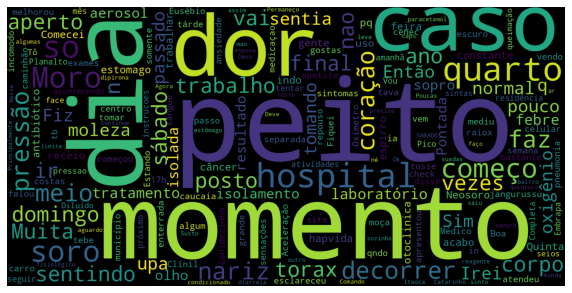





Total of sentences is: 176 for the label: 24


['Não. Ficarei me observando'
 'Não.  Já me ajudou, me sinto até mais calma'
 'Tenho que me isolar deles?' 'devo me preocupar?' 'Vou me ajeitar aqui'
 'Já me sinto melhorando' 'Estou me sentindo mais disposta'
 'Me deitei agora'
 'Sim... Estou deitado,mas qdo me sento pra comer tbm me cansa'
 'Na verdade me perguntaram como eu estava me sentindo'
 'Me passaram uma bombinha' 'Por favor me ajude dra Amanda'
 'Como me isolar dele?' 'Nenhum me atendeu' 'Me sinto fraca'
 'So garganta coçando' 'Me indicaram tomar azitromicina'
 'Vocês estão me ajudando muito' 'Devo me preovupar?'
 'Coriza tive so anteontem']


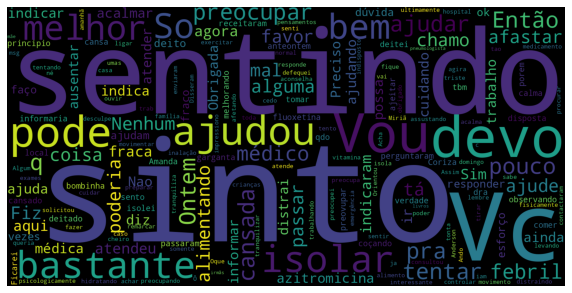





Total of sentences is: 154 for the label: 25


['Ta bem' 'Estou conseguindo treinar estudar ontem fiz tudo' 'Tudo'
 'Tá bem.. vou fazer isso.' 'Praticamente tudo' 'Tudo bem' 'Tudo bem.'
 'Tudo bem. Mais uma vez obrigado.' 'Ok . tudo bem , obrigado'
 'Não, tá tudo bem' 'TA bem' 'Voy ficar bem' 'Sim bem melhor'
 'Tá tudo bem' 'Não tudo bem' 'tudo serto brigado' 'Estou bem melhor'
 'Não por enquanto tá tudo bem. Obrigada' 'tudo bem' 'Sim, tudo bem']


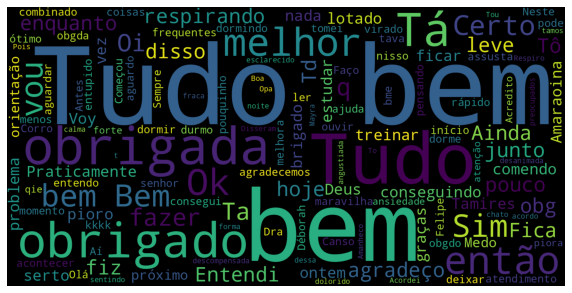





Total of sentences is: 540 for the label: 26


['Acabei de enviar'
 'Preciso de alguém pra ir na casa das minhas bichinhas'
 'Gosta de ajudar outras pessoas'
 'Hoje de manhã senti um pouco de falta de ar. Sinto uma das narinas entupidas'
 'Nem nos postos de saúde? De bairro'
 'Dentro de casa com serviços domésticos'
 'E agora de madrugada meu filho de 1 ano começou febre de 38 graus'
 'Tenho medo de ficar doente' 'Q tipo de cha posso tomar pra relaxar'
 'Cuido da minha mãe,  idosa tem problema de mal de parkson'
 'De madrugada fique cansanda'
 'Procurei o posto de saúde o médico fez a prescrição de medicamentos'
 'Deste de ontem' 'Estou fazendo uso de paracetamol'
 'Quando invento de levantar' 'Tenho plano de saude'
 'Melhorei de ontem pra hoje , já estou tomando medicação'
 'Tive tambem dois episódios de vômitos' 'Vomitei de tanto tossir'
 'Gosto de vê filme']


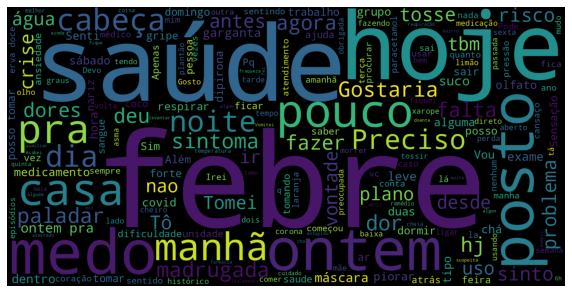





Total of sentences is: 185 for the label: 27


['contra um câncer' 'Um pouco escura' 'Um pouco'
 'Alguns espirros mas bem longe um do outro' 'Me vem um calor'
 'Pra fazer um teste?' 'Tenho um filho pequeno' 'Melhorar um pouco vou'
 'Hoje estou um pouco melhor' 'Um suaseira' 'Devo procrar um upa?'
 'Um pouco,' 'Ao tomar um antialérgico (celerg) senti um alívio.'
 'No início senti um alívio do nariz por usar um antialérgico'
 'Um pouco melhor' 'Incômoda um pouco'
 'Agora,  um certo incômodo ou desconforto' 'Incomoda um pouco'
 'Ou esperar um pouco ?' 'Um cansaço']


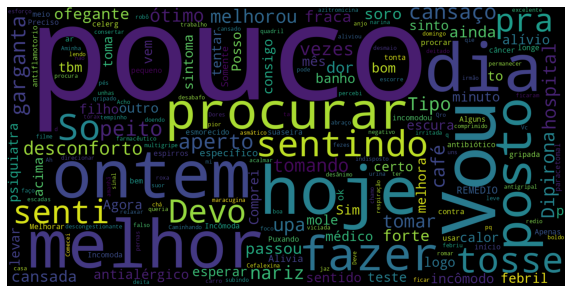





Total of sentences is: 266 for the label: 28


['Sim' 'Sim, meus dois irmão' 'Sim! Sim' 'Sim.' 'Sim!' 'Sim consigo'
 'Sim pq qundo mim distraio respiro normal' '.sim' 'Tenho sim'
 'Sim. Tylenol DC' 'Sim sim' 'Sim estou' 'Quero sim' 'Estou sim'
 'Melhora sim' 'Sim , muito enjoo' 'Tomo sim' 'Como a pessoa sim prevenir'
 'Recebi sim' 'Recebi sim!']


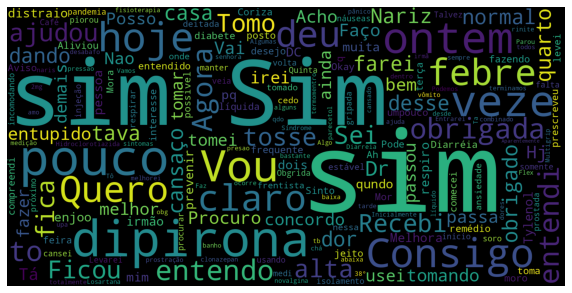





Total of sentences is: 59 for the label: 29


['so tomo anticoncepcional' 'No momento somente isso'
 'Tomo so anticoncecional' 'Nao tenho no momento'
 'tomo todas as noites desde a 4 dias tomo' 'Nao tomo medicamentos'
 'No momento ñ' 'E tomo remédio no caso centir febre'
 'Nao trabalho  no momento  estou desenpregada'
 'Temperatura neste momento 36.6⁰' 'Oq tomo?' 'E tomo todo cuidado'
 'Só reniti. Tomo loratadina' 'No momento nao' 'Nessse momento'
 'No momento elas estão bem' 'Estou sem febre no momento'
 'Tomo premidisona' 'Tomo velija 60mg' 'Mais nao tomo remédio.']


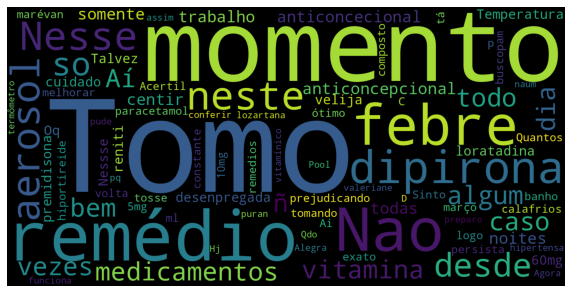





Total of sentences is: 657 for the label: 30


['E como devo proceder' 'E uma vez até minha pressao subiu'
 'E também algo relacionado ao lúpus'
 'Tomei e fui dormir, mas acho q não voltou estava com muita dor de cabeça pra levantar e medir novamente'
 'Só a garganta arranhando e tosse'
 'Não precisei ir pro hospital e nem exame'
 'Porém ele trabalha numa fábrica no pecem e tem contato com muitas pessoas'
 'Vou pedir pra não utilizar. E vou manter somente a medicação pra dor e febre'
 'Certo e sobre meus sintomas qual sua orientação'
 'Agora a febre passou e sinto um desconforto só como.enjoo'
 'Mais isso já faz um mês e meio' 'Minha filha ta tossindo e conçada'
 'Coronavirus e assim ou tem q ter coriza'
 'Preciso retornar ao médico, pois trabalho e preciso levar o atestado.'
 'É sem cheiro e paladar'
 'Estou min alimentando bem mais a fraqueza e muito grande'
 'Ms ela não e tive contato com ela'
 'Como eu disse hoje pela manhã pedi a temperatura e tava dando 37.3'
 'Só tiver aquel

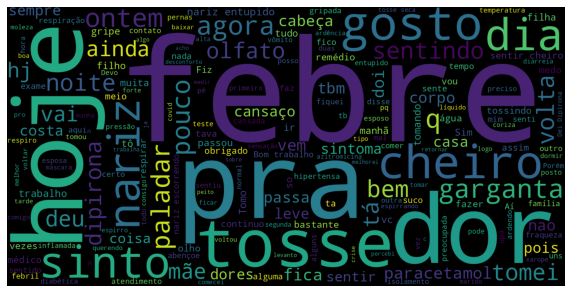





Total of sentences is: 210 for the label: 31


['Sim! Estou separado das outras pessoas da casa.' 'Da sim'
 'Certo. Isso considerando a medida tirada pelo termômetro na axila ou embaixo da língua?'
 'Por conta da tosse constante' 'Fica mais perto da minha casa'
 'Hje final da tarde cansada' 'Encima da costela'
 'Tomei durante 5 duas Benegripe e  ontem as duas da manhã comecei a tomar xarope'
 'Vc acha necessário eu entrar em contato c o pessoal da vigilancia sanitsria da minha cidade'
 'Eles vai na casa da gente' 'Tenho medo da morte' 'Da Covid'
 'Ou no hospital Leonardo da Vinci' 'Sou profissional da saúde'
 'Area da grande Messejana' 'Posso da a ele'
 'Infelizmente estamos sofrendo bullying por meio das pessoas da rua'
 'Da manha' 'Hoje dê manhã.' 'Só Dipirona e remédio da pressão']


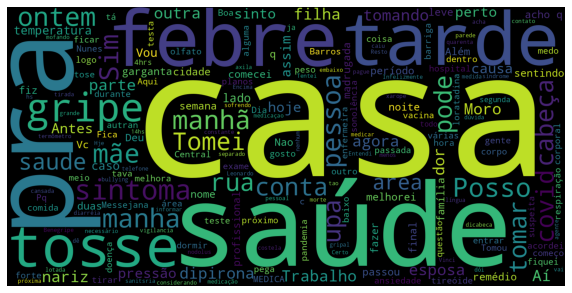





Total of sentences is: 504 for the label: 32


['Não pelo contrário estão ajudando' 'Não costumo ter crise alérgica'
 'Hj não fiz nada' 'Não posso tomar medicação alguma sou alérgica'
 'Ainda não' 'Você entende' 'Ele não está trabalhando'
 'Não sinto gosto nem cheiro tá difícil comer' 'Não obg' 'ainda não'
 'Não vou menor. Estou usando ele'
 'Só fico preocupada porquê a febre não baixa' 'Nao Não tomo nada'
 'Não costumo fazer isso' 'linfoma não Hodgkin' 'não sei onde'
 'Hoje ele não teve febre' 'Não só isso mesmo' 'Hoje não'
 'Não tomei ainda']


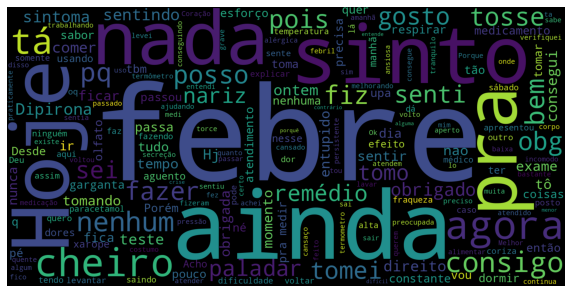





Total of sentences is: 670 for the label: 33


['Mãe , tia que me criou, tio,'
 'Não foi feito nenhum exame. O médico passou Dipirona 1g, se febre. Alexofedrin D, pra Corisa e espirros. Sekí xarope pra tosse. Pediu pra me manter em casa.'
 'Sintomas hoje:  * dor de cabeça, mal estar estomacal e falta de apetite. * Dia 24/04, sentí os primeiros sintomas. Espirros e corisa. Dia 20, tive contato com covid positivado. * Fui ao médico. Receitou: -Dipirona 1g, se febre ou dor. -Seki, se tosse. -Alegra D, se espirros. * Não fiz nenhum teste.'
 'Falta de ar, não. E à noite, fico febril. Tou conseguindo controlar a febre com a Dipirona. É durante o dia, a temperatura é normal.'
 'Já cheguei a 38⁰. Essas últimas noites, 37,8⁰ e 37,9⁰.'
 'Consigo me manter bem com a Dipirona. Mas hoje, tive dor de cabeça e mal estar. Uma gastura no estômago. Sem vontade de comer.'
 'Dor na nuca e nas costas bem acentuada. É um pouco de pigarro na garganta.. Eu tossi durante a aula'
 'Como se eu tivesse dormid

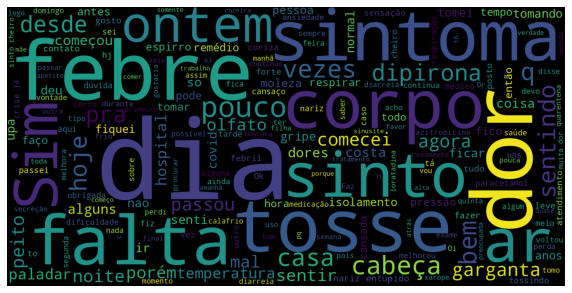





Total of sentences is: 594 for the label: 34


['Faz sim! Mas eu temo perde los todos de uma vez! Eu amo meus idosos. Elas choram e vão buscar as outras pra passar lá na casa delas!'
 'Sim. Como eu tenho alergia a muitas coisas, penso que pode ser uma crise alérgica'
 'Tava usando Nasonex, mas a alergologista disse que eu parasse e tomasse o Alektos'
 'Eu tenho Maresis aqui. Pode ser ele?'
 'E como eu faço agora p pelo menos dormir'
 'Eu sei que estou muito é nevosa'
 'Não.  Eu estive no começo dessa pandemia  depois encontrei conforto escutando o Padre todos os dias'
 'Ok. Muitoo obrigada. Na quarta eu vou no hospital das clínicas que é onde sou acompanhada e ja me deixaram ciente que qualquer coisa eu poderia ir no hospital'
 'N. Pois o acompanhamento normal seria para junho. Mas a médica me deu um papel com alguma informações sobre minha doença para caso eu precise ir no.hospital eu apresentar e deixarem eu entrar'
 'Só me tira essa dúvida se eu posso está com o corona ?'
 'Tudo

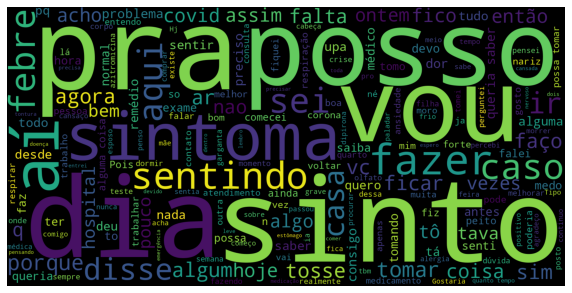





Total of sentences is: 351 for the label: 35


['Quais posso tomar para melhorar a dor e a obstrução nasal'
 'Queria algo para aliviar a tosse' 'Que verifiquei a pressão'
 'A garganta que está muito irritada'
 'Mas percebi q está aumentando a frequência' 'Pq a respiração força né'
 'Mais a dor era maior' 'Pq começou  a tarde'
 'Apenas a diarreia que começou hoje.'
 'Quando lavo roupa, pela manhã e a noite, a tarde quase não fumo'
 'Minha filha esta melhorando, graças a Deus'
 'Hoje deu normal,mas estava entre 37,7 a 38,4'
 'Uma pequena canseira A tosse que não é incontrolável E a febre 38.1'
 'Fui no médico hotem a noite'
 'O primeiro dia chegou a 37 os outros dias tomava logo dipirona quando sentia a febre'
 'Sim , tomo a dipirona passa q está voltando'
 'Só que ela acrescenta a fórmula'
 'Agora enquanto estamos conversando a sensação está diminuindo um pouco, já consigo respirar profundamente'
 'Eu comecei a usar a medicação ontem e já consegui dormir melhor'
 'Respiro normal']


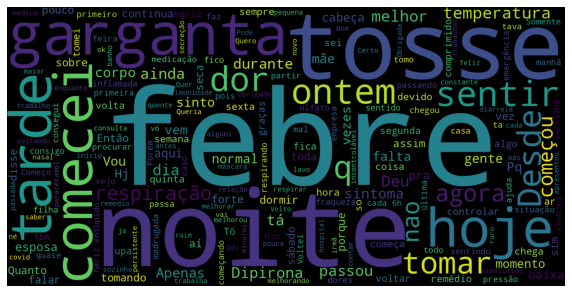





Total of sentences is: 479 for the label: 36


['Dor no corpo, dor nos olhos, sensação de febre, espirros bem esporádicos e sensação de cansaço'
 'A gripe vai fzr duas semanas, no início me deu febre e dores no corpo, hj não sinto mais febre e nem dor no corpo, mas dar um pouco de dor de cabeça e ontem comecei a ter dor de barriga.'
 'Ele tomou dorflex e a dor de cabeça passou'
 'Faz 3 dias q sinto muita dor de cabeça, febre e nariz congestionado'
 'Dor nos olhos e febre e dor no corpo'
 'estou com uma tosse falta de ar e dor de cabeça'
 'E que estou sentindo dor de cabeça'
 'Um pouco de dor no corpo, um pouco de coriza e uma dorzinha de cabeça leve'
 'Deste ontem estou sentindo uns sintomas moleza no corpo, estou ainda com bastante dor de cabeça, tive febril (37.6)'
 'E hoje amanhece com dor de garganta e dor de cabeça'
 'Sentindo  so  um pouco de dor no corpo'
 'Estou com dor na garganta febre nao muito alta e dor debaixo do peito do lado esquerdo'
 'E um pouco de dor de cabeça' 

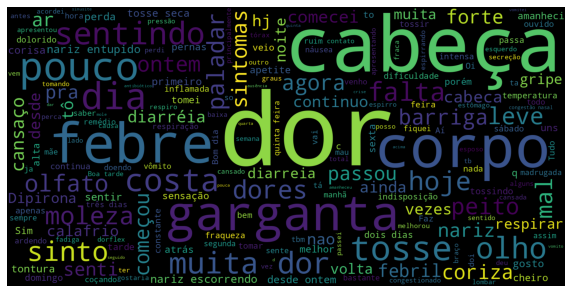





Total of sentences is: 774 for the label: 37


['Não posso tá lá , meu genrro é. Médico e vem aqui em casa, por isso não posso ir'
 'Não sabemos mais o que fazer'
 'Ela é tão forte que é ela que abre a cova pra enterrar nossos mortos e acha natural e não chora'
 'Tem não! Foi difícil eu até fazer o controle no velório'
 'Respiração pra dentro profunda e solta o pouco não sei explicar as vezes tenho muito ar outra vezes pouca'
 'Obrigada. Não não!! Vou tentar fazer o q vc falou'
 'Não é intensa aparenta ser por conta do nariz e garganta' 'Sei'
 'A gente não tinha  muito intimidade'
 'Não sei se é uma virose que eu possa tratar em casa ou se devo ir ao médico devido eu também ter lúpus'
 'Tosse sim mas não é constante. E não tive febre' 'Que não sei explicar'
 'Sim então os sitomas que eu tenho não tem nada haver com esse vírus??'
 'Então como eu não tive febre pode ser que não seja esse vírus pode ser ate mesmo uma virose ne'
 'Mal estar mas não muito,' 'O nariz não está afetado, re

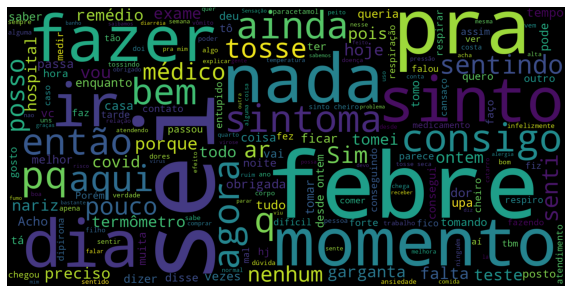





Total of sentences is: 57 for the label: 38


['Passa depois volta' 'E depois volta' 'Mas depois volta' 'Meio fraca'
 'Amarelo' 'Estou meio aéreo' 'Planalto Pici'
 'Fico com moleza devido a dor de cabeça  e sor noa olhos tomo paracetamol  passa ai depois volta'
 'Depois do almoço' 'a febre passa depois sinto febril'
 'Um pouco depois volta.' 'Passa e depois volta' 'Do lado direito'
 'A febre passa e volta depois' 'Hoje a tontura tá pior'
 'Marrom escura lembra sangue' 'Pior.'
 'Passa a dor de cabeça a febre depois volta'
 'muita febre ,toma paracetamol passa e volta' 'pelo pior']


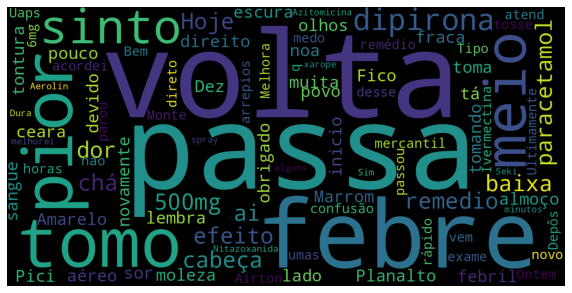





Total of sentences is: 380 for the label: 39


['É minha única esperança' 'Tenho medo' 'Já q sou alérgica' 'Ou melhor'
 'oq devo fazer' 'Melhor né' 'Está' 'Minha mãe'
 'Minha temperatura tá 34.5 35.0 não passa disso'
 'Pq minha neta mora comigo' 'Pré diabética' 'Estou melhor'
 'Hoje estou cansada' 'Hora estou melhor' 'Melhor' 'Acho leve'
 'Achei hoje ela bem melhor' 'Respiro bem pelo nariz'
 'Acordo cedo mesmo indo durmi tarde' 'Minha filha']


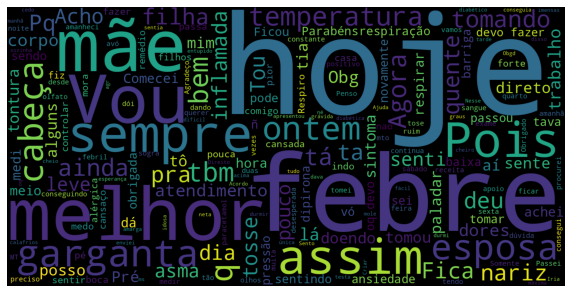





Total of sentences is: 65 for the label: 40


['Tylenol ou paracetamol' 'Continuo tomando paracetamol?' 'Paracetamol'
 'Paracetamol e soro fisiológico no nariz' 'Diabetes' 'Sim, paracetamol'
 'Alprazolam 0.5 mg' 'Paracetamol?' 'Corrigindo, paracetamol'
 'Paracetamol e chá' 'Tomo paracetamol' 'Tylenol sinus'
 'Paracetamol ou Ibuprofeno' 'Obstrução nasal' 'Tylenol'
 'Tomo paracetamol novamente?' 'Atenolol 25mg' 'Cálculo Renal'
 'Tomou agora paracetamol' 'E paracetamol']


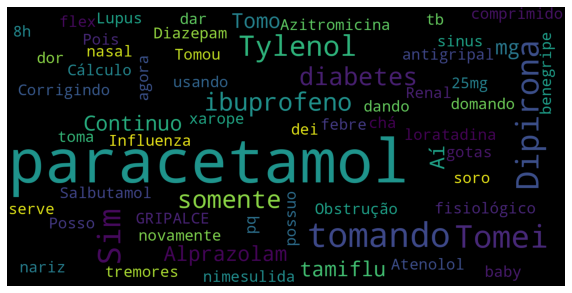





Total of sentences is: 48 for the label: 41


['Eu pergunto é considerado alto esse resultado???' 'Só esse'
 'Continuo tomando esse flamador' 'Vai completar' 'Sou grata' 'vai ligar'
 'Só esse medicamento mesmo' 'Como esse ñ' 'Oi vou iniciar esse aqui'
 'Esse remédio serve pro cansaço'
 'Covid obrigatoriamentente  apresenta esse sintoma?' 'Grata' 'Esse'
 'Esse mês' 'Posso lhe enviar esse laudo' 'Ele sempre toma esse'
 'Esse mesmo procedimento serve pra minha esposa ?'
 'UPA faz esse atendimento?' 'Vcs fazem esse atendimento?'
 'Quanto tempo pra esse vírus sair da pessoas']


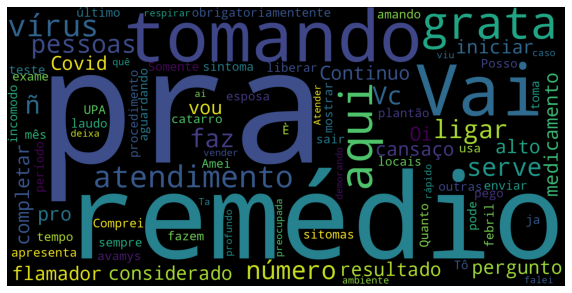





Total of sentences is: 105 for the label: 42


['Lábios secos boca seca' 'Pressão alta' 'Febre baixa,' 'Seca'
 'Saude caixa' 'Evita' 'Tosse seca' 'Dei dipirona' 'Pouca tosse seca'
 'Santa fé' 'Põe água sanitária' 'Desde sexta feira'
 'Pacajus Ceará rua Holanda Campelo  796' 'Sexta feira' 'Bairro damas'
 'Comecei centir febre na quinta feira' 'Tô tomando muita água'
 'Começou sexta feira'
 'Desde quinta feira passada trnho sentido mal.estar' 'Ja dei aerosol']


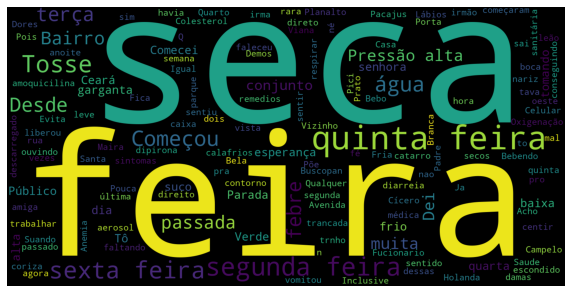





Total of sentences is: 270 for the label: 43


['Nossa família toda é assim!'
 'Minha preocupação é ter uma pneumonia silenciosa.' 'É'
 'É pelo whatsapp tbm?' 'Vai ser difícil é ter vaga né'
 'Não é grande só q sinto dificuldade o q não é normalmente'
 'Já tô faz é tempo' 'Um q é digital' 'Acho q é alto né isso?'
 'Rosileia é a mãe dele' 'É escura' 'É uma dor disviado'
 'Fez pelo plano particular' 'No caso é minha filha'
 'Quem está falando agora é a esposa dele... Ele piorou e foi pra emergência'
 'É o mais próximo' 'Vc é medica?' 'É nas Costa toda' 'Ele é alto risco'
 'O remédio celerg é dela']


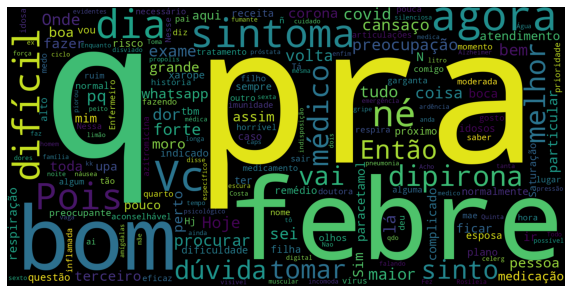





Total of sentences is: 267 for the label: 44


['Um pouco só' 'Só fico preocupada em relação aos medicamentos'
 'Só o coração acelerado' 'Só estamos tomando paracetamol' 'Só isso'
 'Só nariz entupido' 'Só' 'Só diarréia' 'Só faço reeducação alimentar'
 'Só paracetamol' 'Só congestão nasal' 'minha bebê só mama'
 'Só essa mesmo' 'Só febre' 'Só isso mesmo?' 'Só estou tossindo agora'
 'Às vezes só dá uma pontada' 'Só  espirrou um pouco' 'Só temos um quarto'
 'Só nervosismo']


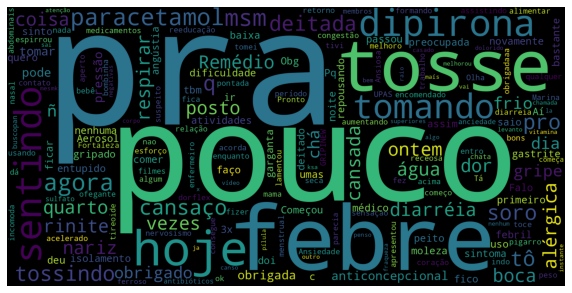





Total of sentences is: 128 for the label: 45


['Tá  certo' 'Certo' 'Tô sozinha' 'Tô preocupada' 'Certo  Obrigada'
 'Tá certo, muito obrigada' 'Está certo' 'Certo, obg' 'Tá certo'
 'certo vou procurar hoje' 'tá certo' 'Ta certo' 'Ta certo?'
 'Certo obrigado' 'Tô' 'Ta certo Dra Juliana' 'Tá certo.' 'Certo então'
 'Ah certo obrigada' 'Tá certo!']


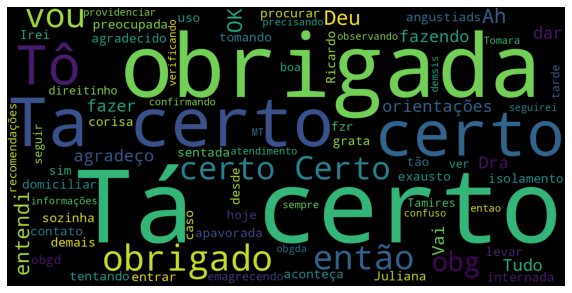





Total of sentences is: 418 for the label: 46


['Tô  muito nervosa Marcela com tudo isso'
 'Estou aguardando vaga virtual com uma psicóloga pra eles'
 'Não! Porque eles se acostumaram com minha tia sendo a cabeça da família'
 'Febre controlada com Dipirona 1g' 'Respiro com mais facilidade'
 'Só estamos com tosse'
 'Estou muito nervosa.  Estou sem senti cheiro e com coceira na garganta'
 'Certo  Com faço com marido? Rsrs que 24no meu ouvido falando sobre o corona'
 'Estou com mi há garganta há 3 semanas irritada'
 'Não posso ir fazer ao médico por enquanto pois moro com 2 criancas que estão com catapora.'
 'Eu posso está com o corona ou é uma gripe?'
 'Estou com minha garganta coçando'
 'Estou com ansiedades e por isso fico com falta de ar'
 'Com meu esposo e meua dois filhos pequenos'
 'mas ainda continuo com o nariz entupido'
 'Meu filho está com 39 graus de febre,dei dipirona a ele 18:10 e até agora não baixa,ele também está com dor de cabeça'
 'Não, mas tava com muito frio'
 'te

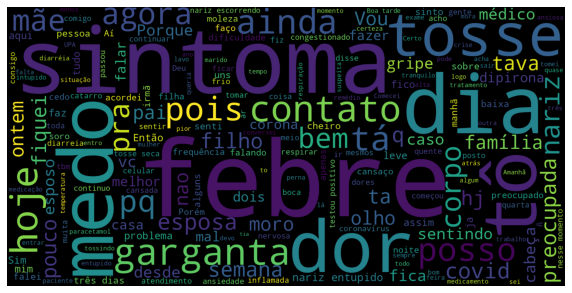





Total of sentences is: 326 for the label: 47


['Mais não sou eu q estou com sintomas' 'Eu não'
 'agora eu nao vejo ninguém, nem meu namorado' 'Amanhã vou no posto'
 'Agr de manhã eu medi dnv tá dando 37.3'
 'Só moramos eu e minha esposa num apartamento'
 'Eu nunca tive problemas com isolamento'
 'ontem tinha garganta inflamada mais eu fiz cha quente'
 'sim eu quero pensar desse jeito pra nao entrar en desespero'
 'Eu fico muito tempo deitado na rede'
 'Eu estou com muito medo não sinto gosto ou cheiro'
 'Meu nariz só fica entupido quando eu vou dormir' 'É só ele eu não'
 'Eu tenho me sentido muito cansado não faço nada'
 'Eu acho que falta oxigênio na minha cabeça' 'Eu já tô melhor'
 'Eu só tomo dipirona' 'Eu não posso tomar nenhum xarope?'
 'Ou então quando eu preucupo  com alguma coisa'
 'Hoje eu tô com uma inflamação na garganta']


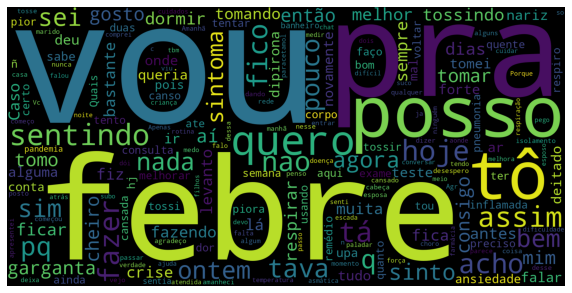





Total of sentences is: 56 for the label: 48


['Então apenas em instituições particulares posso realizar esse teste?'
 'Cert' 'Era apenas isso mesmo' 'Apenas' 'Uso apenas anticoncepcional'
 'Apenas esses aí' 'Apenas dipirona' 'Apenas sinusite e renite'
 'Não, apenas isso' 'Apenas o paracetamol' 'Apenas pelo nariz'
 'Sim apenas febre' 'A dor apenas vem' 'Apenas online'
 'Não senti febre, apenas alguns calafrios'
 'Estou sentindo apenas a respiração pesada' 'Apenas essas coisas'
 'Apenas 37' 'Apenas estes 2' 'Apenas ontem, deu 38°']


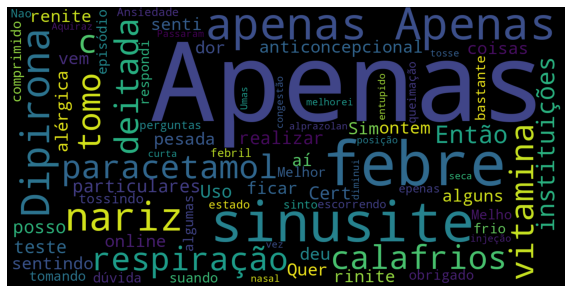





Total of sentences is: 648 for the label: 49


['Obrigada , que Deus  te abençoe' 'Via, 2x por semana'
 'Desde ontem que me sinto mais ruim.' 'Por favor'
 'Se poder me indicar agradeço'
 'Não. As parece que tá,não sei... ontem sentir ele seco'
 'Tem algum laboratório que faz exame particular?'
 'Minha dúvida era do medicamento, Porque é uma irritação que não passa, avermelhada.'
 'Informações sobre covid por favor.'
 'Tenho sentido desde ontem tonturas e sinto que meio febril.. mas n verifiquei esse último.'
 'Consigo sin' 'Que medicação regular seria?'
 'Olá, bom dia. Gostaria de saber como proceder sobre uma questão...  Eu sinto desde ontem uma fadiga no peito, um icômodo e não sinto cheiro de nada. Não senti febre em nenhum momento, mas como são muitas notícias eu fico bastante confusa sobre os sintomas. O que posso fazer? Eu sei que não é viável ir ao hospital logo, mas fico confusa sobre o que posso fazer e se pode ser o vírus. Minha família está de quarentena e meu esposo é o

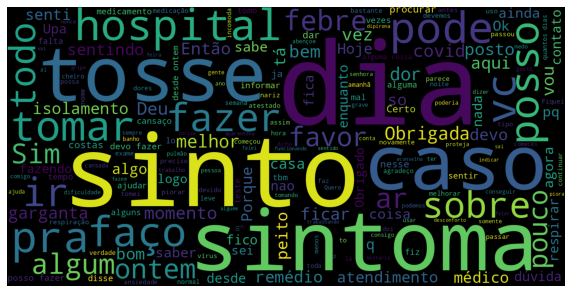





Total of sentences is: 85 for the label: 50


['Deus abençoe' 'Graças a Deus não' 'Graças a Deus' 'Gracas a Deus'
 'Sim Dra, obg Deus lhe abencoe' 'Amém, Deus nos dê saúde!!'
 'O mais graças a Deus está bem' 'Hum' 'Graças a Deus não passa de36'
 'Ok obrigada pelas informações  Deus lhe abençoe'
 'Hj estou me sentindo bem Graças a Deus'
 'Graças a Deus me sinto muito bem' 'Graça a Deus'
 'Mais con a covid nao graca DEUS'
 'As duas crianças da casa não pegaram ainda Graças a Deus'
 'Ok grato... Deus abençoe a todos' 'Se Deus quiser!' 'Deus lhe abencoe'
 'Deus abencoe' 'Graças a Deus não.']


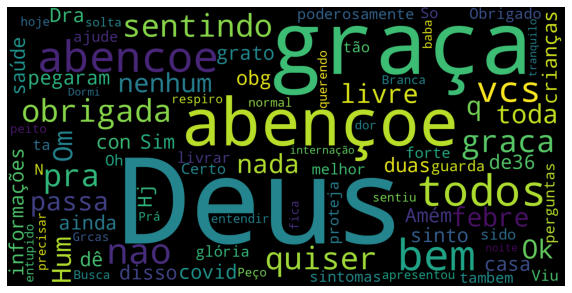





Total of sentences is: 241 for the label: 51


['Como faço?' 'como devo proceder'
 'Ficou cansada como se fosse uma alergia' 'como devo agir.'
 'como saber se é corona vírus'
 'É porque sinto sufocado , como tivesse afogado' 'Como?'
 'Como sei se é covid?' 'Como se fosse coçando' 'Como remédio' 'Como faço'
 'Mal esta  Como se estivesse com muito cansasso'
 'Só incômodo na garganta. Tipo como se fosse secreção Mas dor não!'
 'Hoje senti um mal estar,  suor frio como se fosse desmaiar'
 'Como se tivesse travada' 'Como se tivesse alguma secreção mas bem pouca'
 'As vezes tusso e como se viesse um pigarro' 'Como se fosse dor muscular'
 'Sim, como se tivesse com secreção na garganta' 'Tipo Tampa']


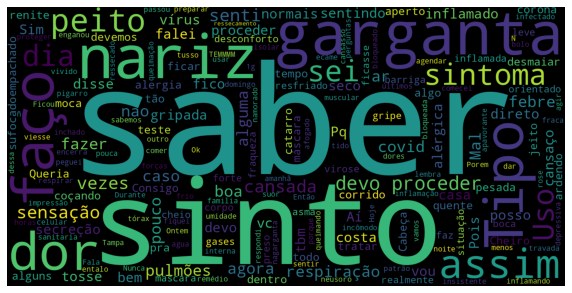





Total of sentences is: 171 for the label: 52


['Fica com Deus! Thau!' 'Obrigada!' 'Entendí!' 'Obrigado!'
 'Certo. Obrigado!' 'Okk, brigada!' 'Obrigado! :)' 'Obrigada!!'
 'Obrigada. Pra vc também!' 'Bia tarde!' 'Não.Obrigada!' 'Certo! Obrigada'
 'Ok !   Obrigada !' 'Claro! Tudo que você mandar! Muito obrigado!'
 'Muito obrigado, Stefane! Pela atenção e pelas explicações.'
 'Agradeço demais!' 'Faz 30 min!' 'Muito Obrigado, Luciana!'
 'Por enquanto! Não! Agradeço demais!' 'Obrigado! Bom trabalho pra você!']


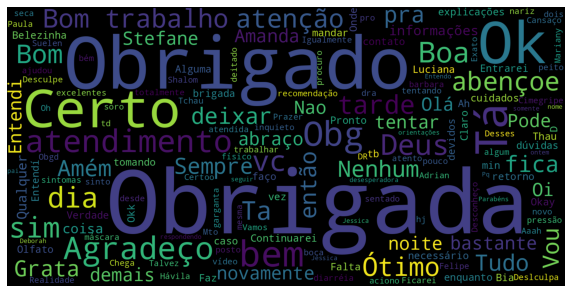





Total of sentences is: 269 for the label: 53


['Fiquei mais nervosa' 'Hoje não tenho mais   Foi so nos primeiros dias'
 'Há uns 3 dias não sinto mais nada. Estou sem sintomas'
 'Muito obrigada pela atenção, estou mais tranquila.'
 'Mais estou usando soro' 'Nao tá mais cossando a garganta'
 'Não irei mais' 'ok, vou tentar ficar mais relaxada'
 'Mais assim eu trabalho em uma unidade hospitalar' 'Pouco mais tenho'
 'Respiração  mais  rápida' 'Mais ou menos 24 horas sem febre'
 'Sou alergica' 'No começo parecia muito mais uma gripe'
 'Agora parece mais uma crise alérgica' 'Mais do lado direito'
 'há mais ou menos uns 4 dias mas não sinto mais febre' 'Mais ou menos'
 'mas nao tenho mais febre' 'Mais estou melhor hoje sim']


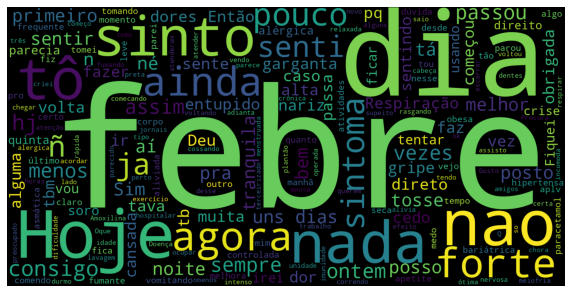





Total of sentences is: 187 for the label: 54


['Um pouco dor no corpo' 'Dor no corpo todo' 'Dor no corpo'
 'Tive febre e dor no corpo' 'E dores no corpo'
 'Só a respiração muito difícil e dores no corpo'
 'Hoje estou com dor no corpo' 'E dor no corpo'
 'Estou 5 dias com febre e muita dor no corpo' 'No corpo'
 'Com muita dor no corpo e a febre continua'
 'Ele sente muitas dores no corpo e essa febre' 'Uma moleza no corpo'
 'Dor no corpo, moleza e náusea' 'Porém a dor no corpo e só nas costa'
 'Está com secreção e dor no corpo' 'e dores no corpo'
 'Estou com muita dores no corpo e febre' 'A dor no corpo não'
 'Só com dores no corpo']


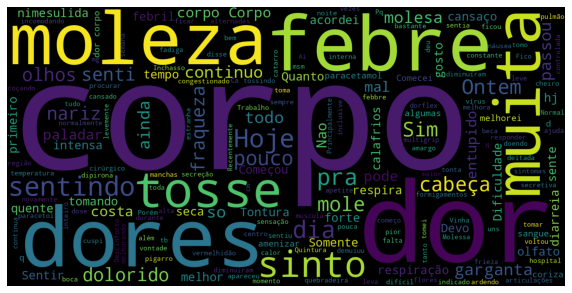





Total of sentences is: 168 for the label: 55


['Boa noite!' 'Ola, boa noite!' 'Domingo a noite'
 'Acordo várias vezes a noite' 'Obrigada, boa noite.'
 'Fiquei febril a noite' 'Só a noite' 'Quinta feira a noite'
 'Ola, boa noite' 'Boa Noite' 'Olá boa noite' 'Não obg e boa noite'
 'Boa noite Jussara' 'Olá,  boa noite.' 'Só agora a noite' 'boa noite!'
 'Boa noite Obg' 'Obg. Boa noite.' 'Boa noite!!' 'Boa noite Fabiana']


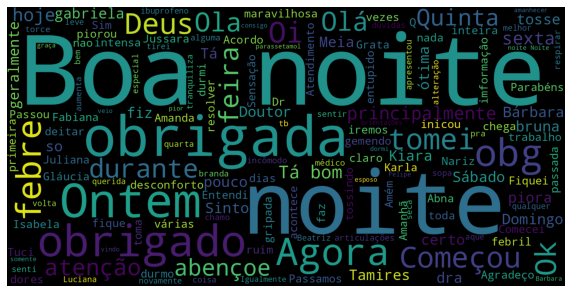





Total of sentences is: 318 for the label: 56


['Tou tomando Alexofedrin pros espirros e Corisa. É pra eu suspender?'
 'Detalhe eu to sem o olfato e paladar.'
 'Isso também influencia em eu ser "imune" aos sintomas do covid 19'
 'Sim, começou ontem. Sinto dor nas costas e na região do peito. Eu respiro bem, só tenho dificuldade quando o nariz está entupido. Quando eu respiro, sinto dor nas costas'
 'Eu tenho. Mais ele n desentope nada  kk'
 'Eu continuo tomando paracetamol em 8 e 8hrs então ?'
 'começou logo quando eu tive que ficar em isolamento e minha mae teve que continuar trabalhando, a preocupação e  o medo q eu sinto dela pegar essa doença é diária e eu também me preocupo comigo por morar junto com ela'
 'ok, as vezes eu choro pra pôr os sentimentos pra fora'
 'Eu acho q é normal' 'Eu trabalho terceirizada em um hospital'
 'Eu estive Há 7 dias na upa, com cansaço mesmo quando estava deitada, tosse, sem olfato e sem paladar, dores de cabeça e febre'
 'Recepção e atendimento, 

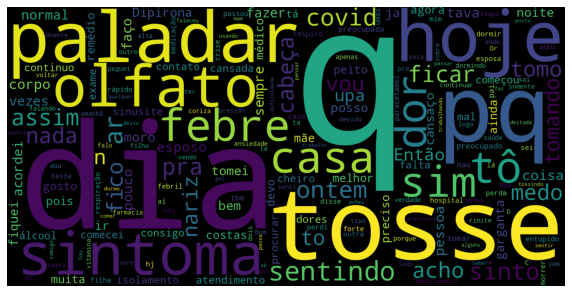





Total of sentences is: 257 for the label: 57


['A febre cedeu' 'devido a pandemia'
 'A barriga ficava ,subindo e descendo  com a respiração' 'A 1 semana'
 'Desculpa, a Net caiu' 'Ontem a tarde' 'Comecou a tarde'
 'É sotirando a duvida' 'A tosse principalmente' 'Ou lavo a louça'
 'A fraqueza' 'Passou a medicação' 'A respiração'
 'Sim. Tenho seguido a risca todas as orientações'
 'Tá  igual a dor  as costas.' 'Estamos a procura' 'Voltei a ter febre'
 'Sim, entendo a orientação e a necessidade para tirar a dúvida'
 'Unico sintoma so a tosse' 'To terminando a amoxilina e neosulida']


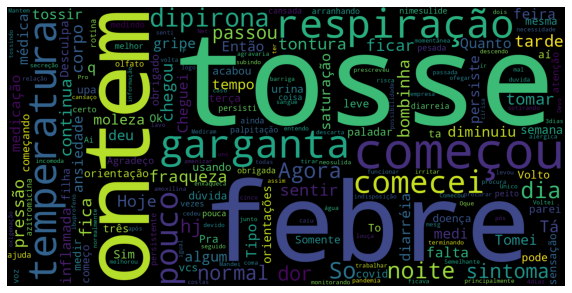





Total of sentences is: 191 for the label: 58


['As minhas pernas  ficar tremendo sem forças'
 'tô sem olfato e sem paladar e moleza no corpo' 'E sem animo pra nada'
 'Sem febre' 'Sem' 'Um pouco sem ar' 'E sem olfato' 'To sem sentir gosto'
 'Eu estou sem olfato nem paladar' 'Nariz ecorrendo sem tose'
 'Nem cansaço'
 'Somente às vezes o nariz coça muito sem secreção, tusso às vezes'
 'Tusso às vezes e sem secreção' 'nem tosse'
 'E hoje amanheci sem paladar e sem olfato' 'Coriza,e sem olfato'
 'Estou só sem sente cheiro e gosto' 'Sem dúvidas! Obg'
 'sem olfato e sem paladar' 'Sem sentir cheiro gosto']


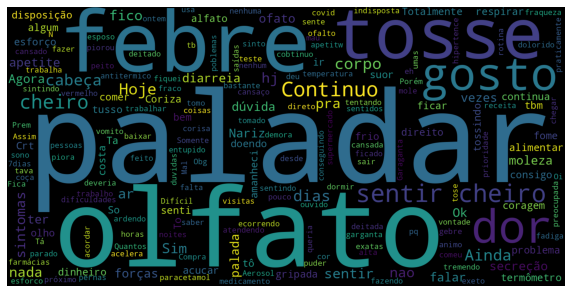





Total of sentences is: 94 for the label: 59


['Corisa*' 'Barriga*' 'Mentir*' 'Horas*' 'Esclarecer*' 'Pouco*' '*'
 'Medir*' 'Incomodado*' 'Me*' 'Esse*' 'Tomar*' 'Contaminação *' '*sinto'
 'Sempre depois*' 'Teve*' 'tosse*' 'Muito*' '*Amaralina' 'Vou*']


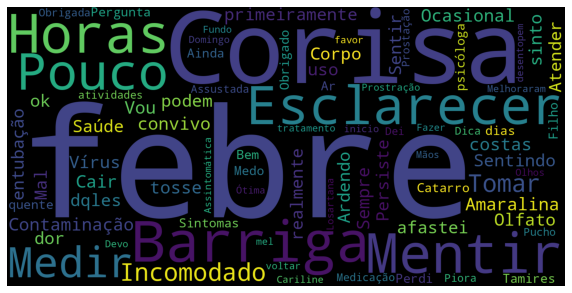





Total of sentences is: 120 for the label: 60


['Ok' 'Ok obg' 'okay' 'Ok..obg' 'Ok !' 'Ok!' 'Ok!!' 'Ta ok' 'Ok Obrigada'
 'Ok  me chamo andrei' 'Ok obg ana' 'Ok obrigado' 'Ok Dra. obrigado'
 'ok obg.' 'Ok.' 'ta ok' 'Ok. Obrigada' 'Ai' 'Ok, obrigada!'
 'Ok, obrigada']


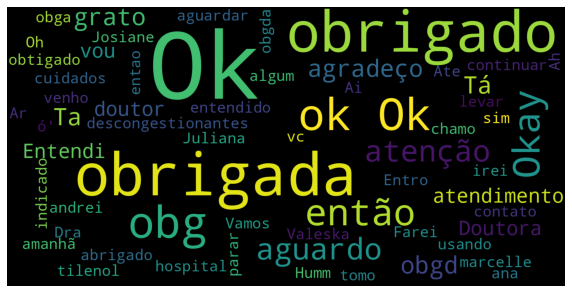





Total of sentences is: 277 for the label: 61


['Ok. Entendí.' 'Voi recomendação médica.' 'Ótimo.' 'Entendi.'
 'Ele teve um infarto aos 19anos ....tem 45'
 'Certo....mais fique preocupada c os batimentos' 'um mal estar....'
 'Então  amanhã vou ficar atenta....muito obrigada, boa noite!!'
 'Acabei tomando azitromicina..aliviou' '3...ultima hoje...tomei a pouco'
 'Não...' 'Farmacêutico...'
 'Moro com meu pai...sobrinhos estão aqui há 2 meses...tenho um irmão'
 'nariz entupido.' 'indisposição.' 'Sim...passa.' 'Sim. Estou.' 'Sábado.'
 'No Hospital Antônio Prudente...'
 'Toma Artrolive pra uma lesão no joelho...somente isso!']


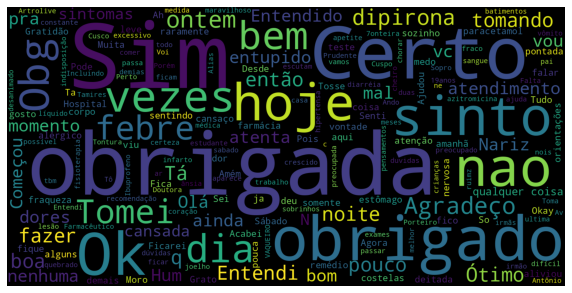





Total of sentences is: 88 for the label: 62


['Tá  bom' 'Tá bom Dra.' 'Tá bom' 'tá bom' 'Ta bom' 'Erva doce tbm è bom?'
 'Tá bom..' 'Obrigado. Tenha um bom trabalho' 'Tá bom.'
 'Bom dia Ermelinda' 'ta bom' 'Bom trabalho' 'Assisto um bom filme'
 'Tá bom então obrigada' 'Bom sucesso'
 'Certo obrigado pela atenção um bom dia a ti' 'Obrigada! Bom trabalho'
 'Quero ficar bom moça' 'Bom dia e bom trabalho' 'Obrigado bom dia']


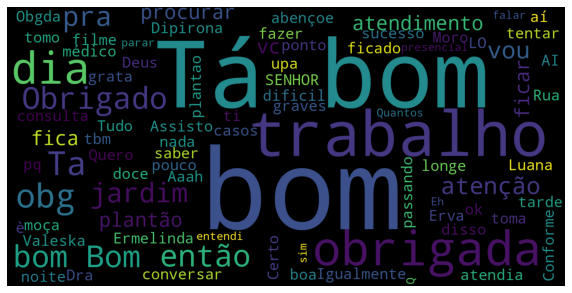





Total of sentences is: 312 for the label: 63


['Entalo na garganta e dor no estomago' 'Na verdade apareceu 110x80'
 'Posto Aida Santos na escola cies' 'Ta'
 'Na verdade ontem ele teve uma febre alta'
 'Tive febre na madrugada, tomei dipirona'
 'Tá com uma tosse seca, dor estranha na garganta,uma falta de ar,uma secura na boca'
 'O susto foi só na hora' 'Faço tratamento só na maternidade escola'
 'Morava na granja portugal' 'Já está na segunda cartela'
 'Estou com pedra na versicula' 'Ta bon' 'Moro na itaitinga'
 'Dipirona serve pra dor na garganta' 'Ela ta espirrando, nariz entupido'
 'Sai' 'Um no na garganta' 'Estou com um incômodo na garganta'
 'Entendi.. na minha tosse tem catarro amarelado']


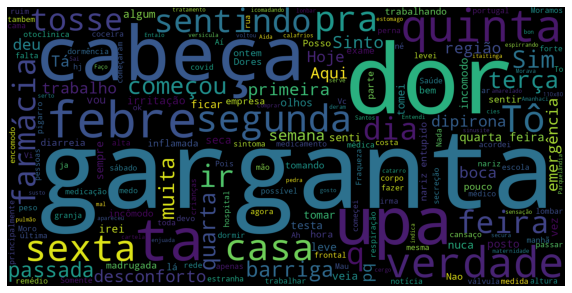





Total of sentences is: 168 for the label: 64


['Sim uma vez, deu 37.7' 'Era uma infecção intestinal'
 'Estou dando repoflor' 'Fui me consultar uma vez só' 'Uma bombinha'
 'Uma vez' 'Comer uma alimentação saudável' 'Só uma vez'
 'Tive uma leve dificuldade para respirar' 'Obrigada mais uma vez'
 'Se possível mim responda só uma coisa' 'Sinto uma fraqueza'
 'Fui a uma emergência cardiológica' 'Tenho uma dúvida.'
 'Ah tenho uma dúvida' 'uma ultima duvida' 'Obrigada mais uma vez!'
 'Uma dor lateijante só do lado esquerdo' 'Uma clínica geral'
 'Hoje começou uma tosse seca']


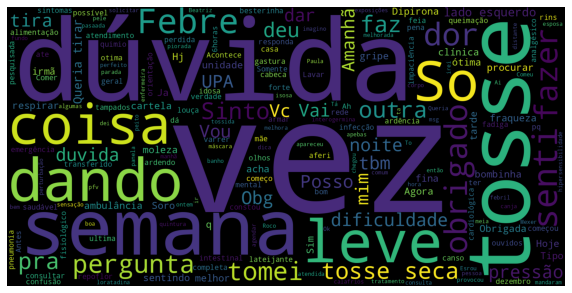





Total of sentences is: 171 for the label: 65


['Pra  ficar tranquila' 'Moro sozinha' 'Pra você me indicar' 'pra vender'
 'Pra ir' 'Tb acho' 'Vou me arrumar pra ir'
 'Nao faz, ela fica direto con a boca aberta pra respirar'
 'Pra você também!' 'Pra dor' 'Estou vendo aqui pra onde vou.'
 'Pra vc tbem' 'Pra desinfeta-los' 'Pra vocês também'
 'Só queria um remédio pra inalar no nariz pra passar esse ardor'
 'Tô fazendo essa consulta pra ele' 'Vou ligar pra lá' 'Levanto pra comer'
 'Quando olho pra cima' 'Ele toma remédio pra pressão']


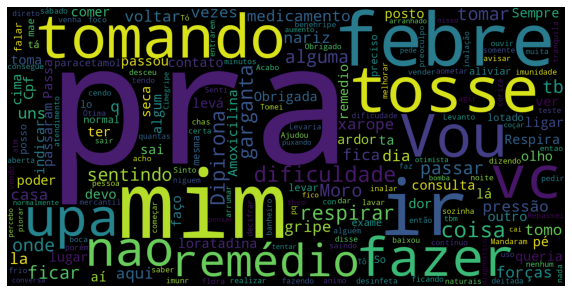





Total of sentences is: 66 for the label: 66


['Raramente fico doente' 'estou indo' 'Quando fico em pé'
 'Quando estou de mascara fico mais angustiada' 'Ora'
 'e pela mesma dor fico suando frio' 'Mais se estou quieta fico normal'
 'Fico tomando dipirona é chás?'
 'Eu fico só no quarto posso fica sem máscara' 'Fico inquieto'
 'Ok fico grato' 'Mas fico enjoada sempre' 'Fico só cansada'
 'Tipo quando fico parada'
 'So quando fico doente só quando fico engripado'
 'Acho e fico muito ansioso' 'Fico preocupada pq posso contaminar sei lá!'
 'Então fico mais tranquilo' 'Fico desesperado'
 'secreção nariz e qndo entope fico respirando curto']


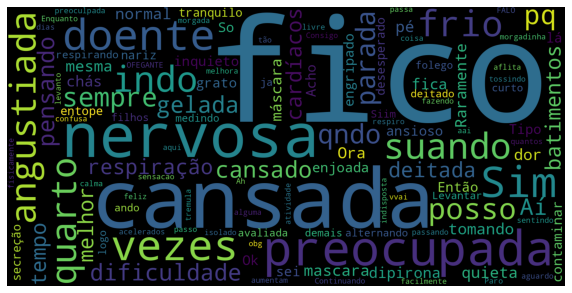





Total of sentences is: 136 for the label: 67


['Gripe' 'Obgda!!!  PELA ATENCAI' 'Obrigado' 'Pela manha' 'Pela amanhã'
 'Muito obrigado pela ajuda'
 'Muito obrigado pela atenção . bom trabalho para vc'
 'Obrigado pela atenção' 'Mim ajuda' 'Obg pela atencao'
 'Obrigado desculpa' 'Sexta pela manhã' 'Entendi obrigado'
 'Ontem pela manha' 'Obrigado menina' 'Obrigada pela atenção'
 'Estou falando pela minha mãe, certo?!'
 'Ficou claro muito obrigado pela sua ajuda' 'obrigada pela atenção'
 'E tive diarreia hj pela manhã']


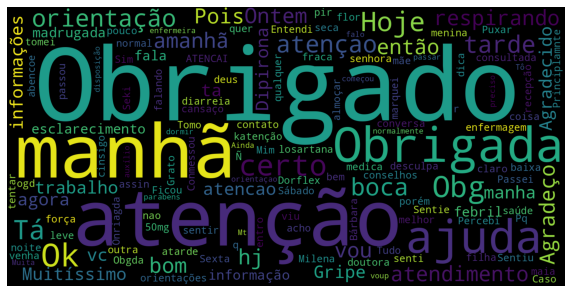





Total of sentences is: 130 for the label: 68


['Rua 922 casa 136 conjunto Ceará.' 'José Mendonça dos Santos 03-05-1976'
 'ELIZABETE MOREIRA DA COSTA LIMA' 'Somente colesterol alto'
 'Agora moro José Walter' 'Fica querendo ficar preto a vista'
 'Pedro dos Santos Bernardo . 01 setembro de 1954. Fortaleza . CPF 12177350387'
 'Rua Safira, Pedras' 'Tenhobum filho pequeno' 'Tenho filho pequeno'
 'No Jangurussu São Cristóvão' 'No posto de saúde do São Cristóvão'
 'Uniclinic São Raimundo  Hospital central' 'Tds portas fechadas'
 'Exato, são sintomas leves' 'Democrito rocha' 'Domingo'
 'Valderilo Viana Tavares 10/10/1971' 'Verde' 'Das mãos']


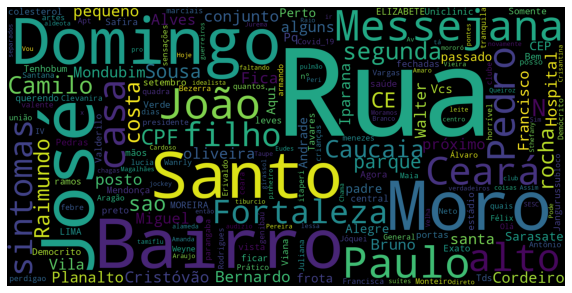





Total of sentences is: 8 for the label: 69


['Olá Amanda' 'Olá Rachel' 'Alice' 'Alias' 'Temperatura corporal 37,6C'
 'Estou co  ansiedade devido essa doença' 'Estes remédios'
 'Daniel Façanha Torres 02/07/1978']


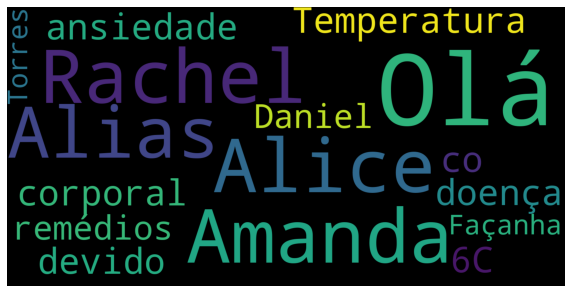





Total of sentences is: 217 for the label: 70


['Ele tem 15 anos,se chama William' 'Aqui tem posto perto'
 'Mais nao tem febre no momento' 'Ela tbm tem sinusite' 'Tem o endereço?'
 'Eu trabalho tem algum problema' 'N tem como' 'Tem 2 meses só'
 'Aqui no Maracanaú tem'
 'Tem 2 dias que tenho febre, agora ela estar em 37,5 tomei paracetamol tem uns 40 mim'
 'Tem algum funcionando nesse período?' 'Ela tem asma alérgica'
 'Nesse caso tem q tomar alguma medicação?' 'Vc tem razão'
 'Tem alguém pra atender' 'Não tem' 'Tem não'
 'Na casa, tem três pessoas desse jeito' 'Tem algum diagnóstico?'
 'Não tem prescrição tbm esse remédio']


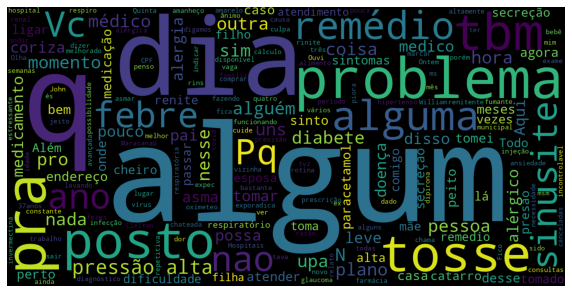





Total of sentences is: 265 for the label: 71


['Já estou a 18 dias' 'Tá certo. Vou cumprir os 14 dias então.'
 'Tem uns 4 a 5 dias' '4 dias hoje' 'Faz 3 dias'
 'Passei 4 dias com febre de 38.7' '12 dias hj'
 'Aconteceu 2 dias seguidos' 'A uns 4 dias atrás'
 'Estou a 3 dias c um certo mal estar' 'Tem 3 Dias'
 'Mas acredito que tenho melhorado no decorrer dos dias, os primeiros dias foram piores'
 'uns 3 dias'
 'Gustavo Hempel Bezerril CPF: 97260908300 Data Nascimento 05/05/1983'
 'levo 3 dias fazendo' 'tive febre 2 dias'
 'Meus sintomas estão fazendo 8 dias hoje' 'E azitromicina por 5 dias'
 'Já a 2 dias' 'Dias são 18 não 19']


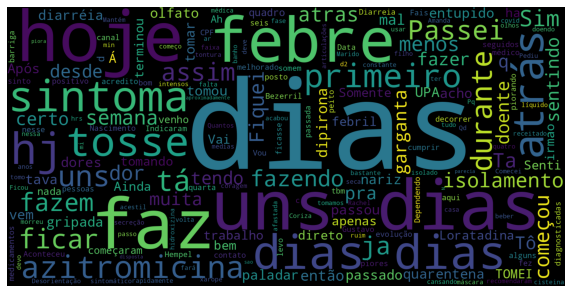





Total of sentences is: 156 for the label: 72


['Não fui ao médico' 'N fui ao medico' 'Ao hospital' 'Então fui ao Hgf'
 'Ontem fui ao posto e me passaram umas medicações'
 'Não, obrigada, vou procurar ir ao hospital'
 'Olá, eu não fui ao médico ainda' 'Fui ao hospital'
 'Não, fui ao hospital do meu plano' 'E quanto ao não estar'
 'Então ele deve ir ao médico?' 'Tenho calafrios ao anoitecer'
 'Em devo ir ao posto de saúde' 'Mais logo voltou ao normal'
 'Nada comparado ao q acontece agora'
 'vou ter que ir ao médico novamente?'
 'Não fui ao médico, Pensei ser um resfriado' 'Não fui ao hospital'
 'Isso tá me prejudicando ao respirar' 'Fui ao otorrino']


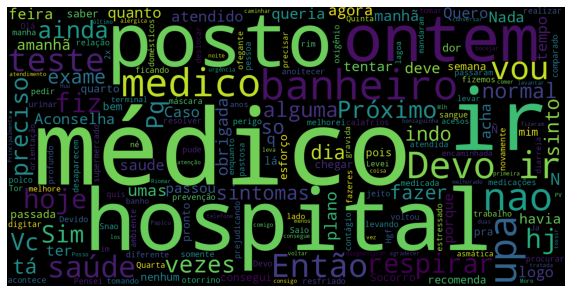





Total of sentences is: 294 for the label: 73


['Tosse, coisa e espirros controlados com Alexofedrin D.'
 'Estou com a voz meia fanhosa' 'Com um aparelho q comprei na farmácia'
 'Com o mesmo aparelho' 'Tive febre so 2 dias e agora estou com tosse'
 'E com fraqueza' 'Com o tempo vdc' 'Estou aliviada com as informaçoes'
 'Meu filha com mal-estar,  meu filho com muita tosse.  E eu com muitaaa dor no corpo e na cabeça'
 'Na quinta-feira meu filho com 38° , minha filha com 37,9° e eu com 36.9°'
 'Mas estou cumprindo o isolamento total com ele'
 'O meu corpo continuo com dores,não mandou eu ficar em isolamento domiciliar, estou com muita dor na cabeça.'
 'Ta com us 40 minutos'
 'Começou com uma gripe comum mais agora so a tosse'
 'To aqui desesperada achando q to com convid'
 'Então ja entrei com amoxilina e antiflamatorio'
 'Tenho dúvida com a questão do isolamento'
 'Mas sempre temos contato uma com as outras'
 'Meu marido estar com estado febril e sempre com a imunidade baixa. Torce c

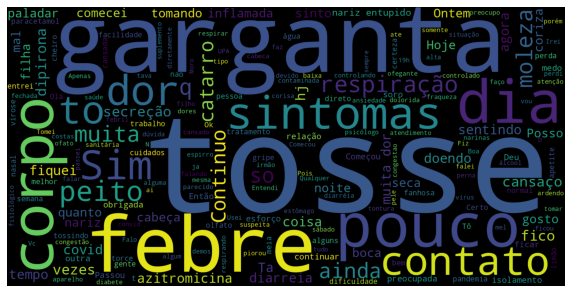





Total of sentences is: 36 for the label: 74


['Daqui a pouco ja estou ruim de novo'
 'Passou a madrugada com febre de novo' 'Melhoro depois volta de novo'
 'Tomo dipirona de novo?' 'Não precisei dar a ele de novo'
 'Verifiquei agora de novo minha febre , deu 36.9'
 'Aí hoje de manhã de novo' 'Novo' 'Banco'
 'Acabei de ver de novo, ela tá com 38,2' 'Mais vou levar de novo'
 'Vou levar no posto de novo.' 'Mais longo voltar de novo'
 'Quero faz de novo pra saber se estou curada' 'Fina' 'Sou eu de novo'
 'Baixa pouco c meia hora sobecde novo' 'E tem febre de novo'
 'Estava baixando agora parece aumentar de novo'
 'medi agora de novo a temperatura deu 36.8']


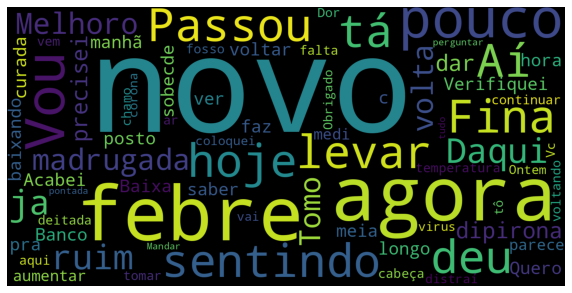





Total of sentences is: 180 for the label: 75


['Já , elas ver os jornais, são orientadas' 'Choro todos os dias!'
 'Todos esses sintomas consigo controlar com os medicamentos.'
 'Verifico todos os dias' 'Todo os dias em confiro'
 'Os batimentos cardíacos dele deu 102'
 'Todos os sintomas foram desde semana passada'
 'Ontem trabalhei mas com todos os cuidados' 'Todos os 5 dias'
 'Queria entender os sintomas'
 'Tenho dois colegas de trabalho que estão com os sintomas parecidos,mas só soube disso dias depois que comecei a apresentar os sintomas'
 'Todos os postos estão funcionando?' 'Pra aliviar os sintomas?'
 'Quais os medicamentos podemos tomar' 'Os dois'
 'Não fiz o teste, porém estou com todos os sintomas'
 'Os dois têm 70 anos' 'Aaa e os olhos lagrimejando'
 'pra os outros sintomas q fazo' 'Deus os abençoe']


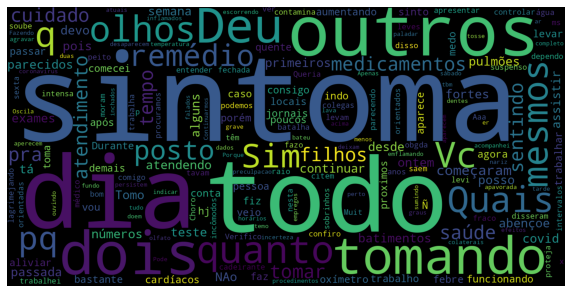





Total of sentences is: 115 for the label: 76


['Febre somente durante a noite durante esses dois dias' 'Dois dias'
 'Com dois dias' 'Três dias hoje' 'Continuo tomando'
 'Sim ,sair uns dias atrás pra uma lotérica' 'Febre alguns dias atrás'
 'Esses a cinco dias' 'Continuo' 'A febre ele só teve dois dias'
 'Tem uns três dias' 'Semana passada' 'Falta dois dias ainda'
 'Tive febre uns 3 dias' 'Quantos dias dura essa tosse'
 'Tive febre dois dias' 'Sábado vai fazer 14 dias' 'Semana retrasada'
 'Estou muito tonta,boca amarga,senti febre dois dias mas já passou'
 'Há uns nove dias']


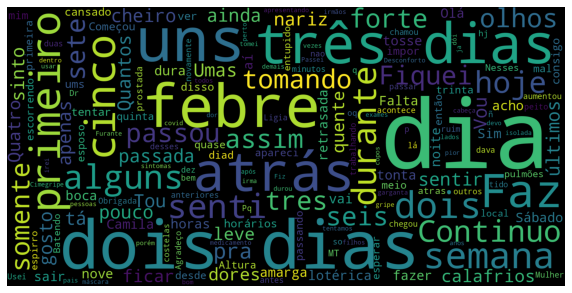





Total of sentences is: 108 for the label: 77


['82 anos toma pra pressão' 'tenho 66 anos' 'Minha mãe  tem 71 anos'
 'Tem 50 anos' 'Ele tem 50 anos' 'Ele tem 4 anos' '2 anos atrás'
 '26 Anos Tenho Ansiedade Espirros e febre' 'a cada 8 horas' '22 horas'
 'Estou a 24 horas sem febre' 'Ele tampa' 'Hoje ta 36.5  a 37'
 'Boca amarga  senti febre 1 vez so 38' '35 años' 'Tenho 27 anos'
 'Estou tossindo há 3 semanas'
 'E como ele tem 64 anos, evito ficar perto dele,'
 '85 anos faz 86 esse mês' '38 graus']


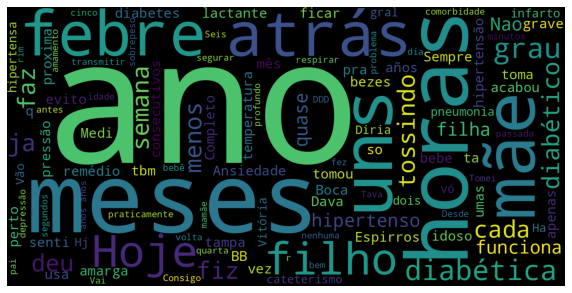





Total of sentences is: 252 for the label: 78


['O meu problema  é  psicológico    nem dormi estou  conseguindo'
 'A 3 meses atrás  quando o meu esposo faleceu' 'É o meu irmão'
 'Eu sinto algo estranho dentro do meu corpo'
 'Tbm tenho espirros e meu nariz está entupido faz 4 dias'
 'Já tem 4 dias q estou espirrando e meu nariz está entupido'
 'Desde q começou perdi meu olfato e paladar'
 'e meu nome é Natalia, eu tinha colocado Gerarda pq antes ela tinha feito uma consulta pelo meu wpp'
 'com meu namorado' 'Estou com medo pois tenho meu esposo, confirmado'
 'Boa tarde! Os atendimentos têm sido pro meu pai!'
 'Como posso evitar passar pro meu filho??'
 'Tem mais 3 pessoaa na minha casa incluindo meu filho'
 'Meu nome e silvangela'
 'Fui nos hospitais do meu plano saúde e os mesmos ñ estão atendendo ninguém isso pode hospital negar atendimento'
 'Valeska  Meu pai está meio mole a dois dias'
 'Eu tive contato com meu primo quatro dias antes dele começar a apresentar sintomas'
 'No cas

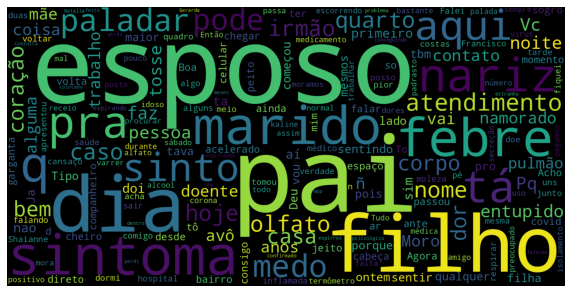





Total of sentences is: 108 for the label: 79


['Precisa n' 'Acho q n' 'Tilenol n fez efeito' 'N' 'N sei se estou'
 'N sinto cheiro ou gosto' 'Entao vcs acham q estou mesmo c covid'
 'Koid D' 'Sum' 'Tenho reniteas l' 'Rinites n' 'N passou'
 'Pq a UPA n recebe ngm' 'Ele tome medicamento p Tireóide.'
 'E n retornaram desde então' 'S' 'O intervalo m'
 'N ta conseguindo dormir' 'tava falando c professor desculpa'
 'Tomo esses 2 p enxaqueca']


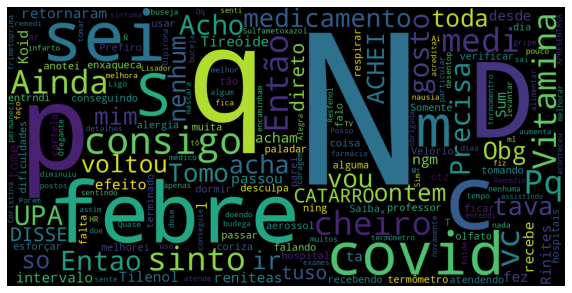





Total of sentences is: 636 for the label: 80


['Tenho rinite e sinusite'
 'Ficarei me hidratando e seguirei suas orientações.' 'E moro sozinha'
 'E p hj o q vc me indica?' 'E tem a taquicardia' 'E tossindo' 'E tosse'
 'E pra ajudar a dormir' 'Coriza e dor no peito'
 'Agora estou melhor. Estou tomando paracetamol em 8 e 8hrs'
 'Tomei hoje as 10h ivermectina 2 comprimidos e azitromicina' 'E Coriza'
 'E me sinto disposta' 'e estou tratamento' 'E próximo'
 'E a cabeça lateja' 'E fiquei um pouvo perto dela'
 'E me sinto  um pouco cansada' 'Ontem tosse seca e quebrada'
 'Tomei celerg  pra tosse e agora dipirona 500']


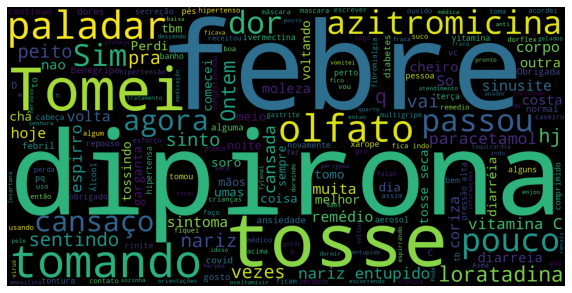





Total of sentences is: 258 for the label: 81


['Eu to com sensação de febre. Mas, não tenho termômetro em casa'
 'Eu ontem tive febre 37,80  A mais de 7 dias tô espirrando muito garganta roca e moleza  no corpo'
 'Qndo eu começo a pensar nessa doença começo fico logo com falta de ar'
 'horrível, eu sempre fui acostumada a estar perto de muitas pessoas, eu estudava pela manhã e tarde, passava o dia fora'
 'eu sei, mas eu sempre fui muito organizada, sempre seguia o cronograma de estudos, mas agora eu tava seguindo meu cronograma de quarentena, e eu nao me sinto bem comigo mesma por nao conseguir segui-lo'
 'Eu de pouquinho'
 'De vez enquando quando eu respiro sinto a dor fina debaixo do peito'
 'E quem me dá força para eu ficar de pé' 'Eu gosto de praia'
 'Eu tenho a sensação que estou com falta de ar por conta da tosse'
 'Eu disse que estava apenas com tosse intensa, ontem passei mal com falta de ar'
 'A de alívio eu já tenho' 'Tenho medo de perder pessoas q eu amo'
 'Antes de eu 

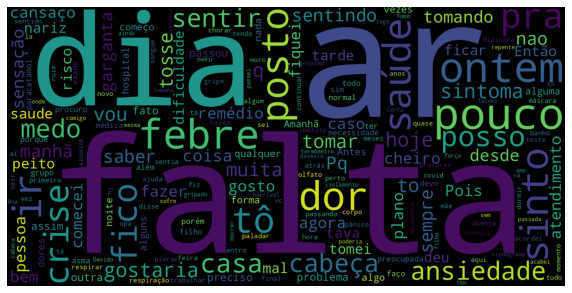





Total of sentences is: 74 for the label: 82


['Boa tarde!' 'Boa tarde.' 'Boa tarde' 'oi, boa tarde'
 'Certo, obrigada. Boa tarde' 'Oi, Luciana. Boa tarde!'
 'Boa tarde Daniella' 'Boa tarde Marina'
 'Oi boa tarde estou com pouquinho de tosse'
 'Boa tarde me sinto anciosa e preocupada' 'Obrigado tenha uma boa tarde'
 'Ok Boa tarde' 'Ficava boa sozinha' 'Boa  tarde' 'Boa tarde Dalva'
 'Clarice Boa tarde' 'Boa' 'Oi, boa tarde' 'Boa tarde Tatiana'
 'Ontem à tarde']


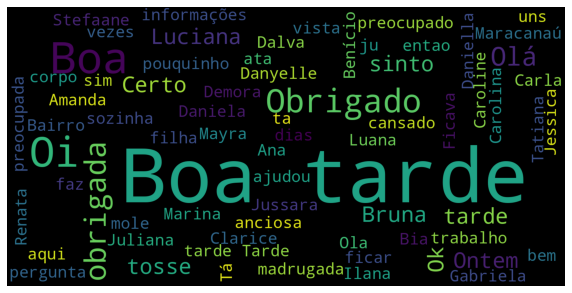





Total of sentences is: 203 for the label: 83


['Eu sei' 'Eu' 'Eu tô apavorada' 'Mas eu sou obesa'
 'Caso eu piore. Vou procurar vc' 'Eu sou pré diabética' 'Agora  sou eu'
 'Olha ana eu sou filha do sebastiao' 'Eu estou com ele direto'
 'Mas eu estou doente' 'Eu agradeço pela atenção' 'Hospital eu fui ontem'
 'eu tenho sim' 'nao q eu saiba' 'eu moro com duas pessoas'
 'Sim eu tenho!!' 'Eu lavo com soro' 'Eu torço quando eu torço chega dói'
 'Ontem eu estava muito ruim' 'eu faço isso']


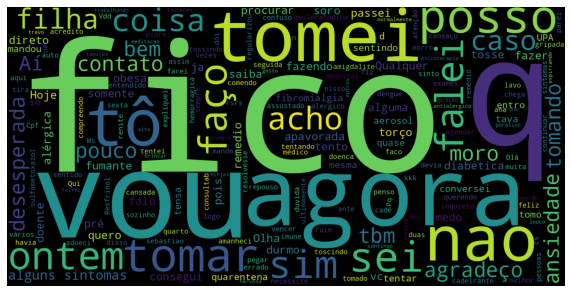





Total of sentences is: 26 for the label: 84


['Oi' 'Oi, Benício' 'Oi estou bem' 'Oi Nelcio' 'Oi Alice' 'Oi Havila'
 'Oi Felipe :)' '?oi' 'Oi Dr Ligia' 'Oi Tamires!' 'Medi' 'Oi, Eduardo'
 'Oi Miria' 'Oi Thaysa' 'Oi, bom diw' 'Oi Ana carla' 'Oi.' 'EMS EXPECTOR'
 'Oi gabriela' 'Oi samira sou a camila']


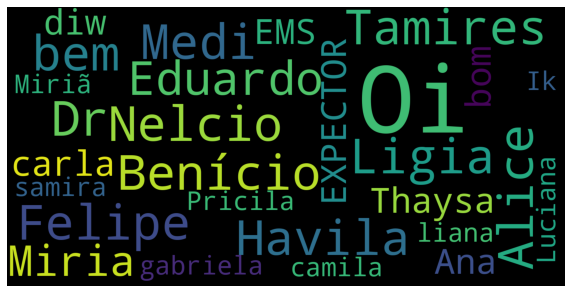





Total of sentences is: 137 for the label: 85


['muita dor na cabeça nas costas com dificuldade de respirar'
 'Está sentindo uma dor nas costas'
 'Estou tomando flamador p dor das costas'
 'Covid dá dor nas costas também?' 'Tomo o que p dor nas costas então'
 'É dor nas costa' 'tosse seca.  Dor nas articulações.'
 'Sinta mta dor nas costas'
 'tenho do no peito e nas costas quando respiro'
 'Hoje eu estou sentindo uma dor forte nas costas do lado esquerdo'
 'Com relação a essa dor nas costas que estou sentindo hoje?'
 'Dor de garganta, calafrios, dores nas costas' 'Atualmente nas costas'
 'Agora atualmente estou com dores nas costas, tosse e dores nos braços'
 'Sinto doer nas minhas costas lado direito'
 'Nesse mal estar é normal a dor nas costas'
 'E estou com dores nas costas' 'Nas costas'
 'São as dores nas costas ardendo' 'Cansaço físico nas pernas corpo']


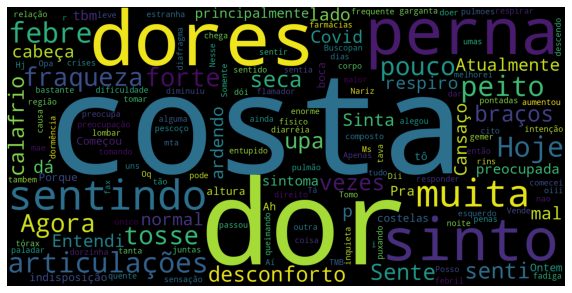





Total of sentences is: 161 for the label: 86


['Só quando tusso' 'quando faço algo' 'Quando tenho febre'
 'quando vai trabalhar' 'Quando respiro fundo sinto dores'
 'Dava convulsão quando criança' 'Quando faço atividade é mais evidente'
 'Quando falo algo' 'Coriza quando espirra' 'pouco nervosa'
 'Tosse leve só quando a garganta incomoda'
 'Quando falo muito me sinto um pouco cansada. Quando olhei estava assim'
 'Sinto cansada quando falo muito' 'Quando falo muito também'
 'Quando colocava' 'Quando faço aerosol com soro melhoro bastante'
 'Quando me movimento' 'Geralmente sinto quando tenho crises da asma'
 'Quando abro o peito dói mais' 'Quando respiro muito fundo doi']


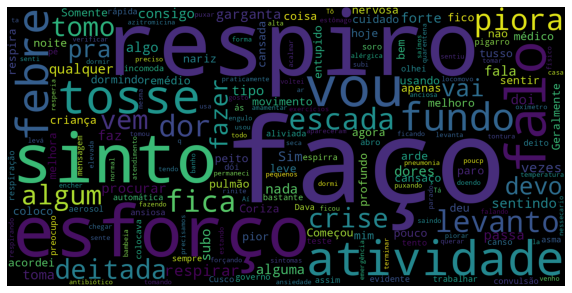





Total of sentences is: 103 for the label: 87


['Até agora não coloquei o termômetro agora' 'Ele vai tomar banho agora'
 'Fez 19anos agora' 'Agora?' 'A temperatura agora 39.5'
 'Agora ela está deitada' 'Agora' 'Vou fazer agora mesmo'
 'Agora está  15x10' 'Deu 37.7' 'Temperatura 36.2' 'Agora estou ofegante'
 '37.8 agora a pouco' 'Tô voltando agora'
 'aferi a temperatura agora esta 35.9' 'Ate agora somente um comprimido'
 'Agora está dando 37,2' 'Comecei agora a tarde' 'Ate agora nao'
 'vou olhar agora']


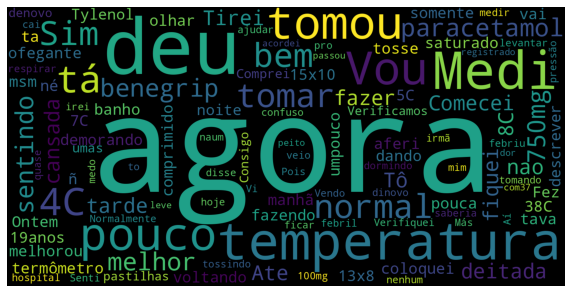





Total of sentences is: 217 for the label: 88


['Com muito medo' 'Todas com' 'Fico logo com medo' 'Tosse com secreção'
 'estou com sonolência' 'estou com tontura' 'Estou com nariz entupido'
 'E hoje estou com esses sintomas' 'Estou com sintomas' 'Estou com eles'
 'Tô com vírus?' 'Com medo' 'Estou com medo' 'Com essa covid19'
 'Quais cuidados devo ter com alguem com alguns sintomas ?'
 'Amanheci com dores' 'Estou com febre 38.7' 'Com um psa 8.7'
 'Bem.esporadicos quando estou deitado com travesseiro alto' 'Tô com sono']


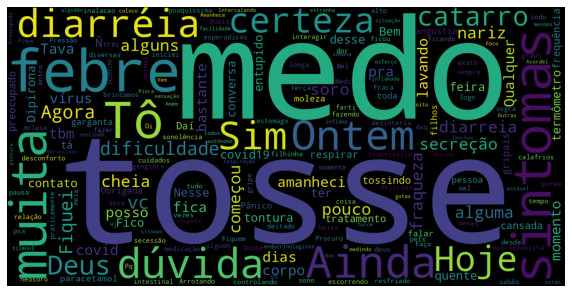





Total of sentences is: 250 for the label: 89


['Dor de cabeça intensa' 'O pior é a dor de cabeça'
 'Há ele sentiu dor de cabeça também' 'Com dor de cabeça' 'dor de cabeça'
 'Dor de cabeça dores nas pernas não sinto cheiro nem gosto das coisas'
 'Dor fina' 'Tomou dorflex pra dor de cabeça' 'Dor de cabeça e febre'
 'Dor de garganta' 'Apenas dor de cabeça leve' 'Estou com dor de cabeça'
 'A 3 dias atrás sentir muita dor de cabeça'
 'Dor de cabeça e dor garganta'
 'Moleza,fraqueza ,Dor de cabeça e febre dor garganta'
 'Senti dor de cabeça ontem' 'Um pouco de dor' 'Muita dor de cabeça'
 'Tosse, dor de cabeça, dor de garganta'
 'A uns quinze dias atrás senti isso. Quentura na cabeça Dor de cabeça Calafrios a noite Garganta inflamada Dores nas juntas Coriza Nariz congestionado Tosse Moleza no começo']


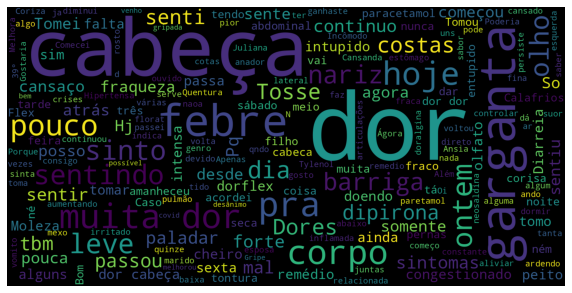





Total of sentences is: 284 for the label: 90


['Estou em casa com 04 pessoas'
 'Mais estava evitando ir em alguma emergência'
 'Tomo o cetoprofeno pq estou em crise da versicula' 'Em repouso'
 'Em quanto tempo'
 'Eu passei um tempo sem ter onde morar quase entrei em depressão'
 'Em outubro'
 'Qria saber quais cuidados devo tomar em relacao a tratamento'
 'Ele está isolado em outro apartamento'
 'Tenho q ficar em isolamento quantos dias?' 'Fiquei em casa'
 'Mas em casa n tenho como ficar em um quarto isolada' 'Entro em comtato'
 'Estou em casa' 'Trabalha em farmácia hospitalar'
 'em casa devo ficar de mascara?' 'Sim, mas foi em uma consulta online'
 'Sim. Totalmente só em casa.'
 'Não, ah momentos em q fica congestionado nariz'
 'Uma amiga tem, ontem ela estava em casa pedi p medir']


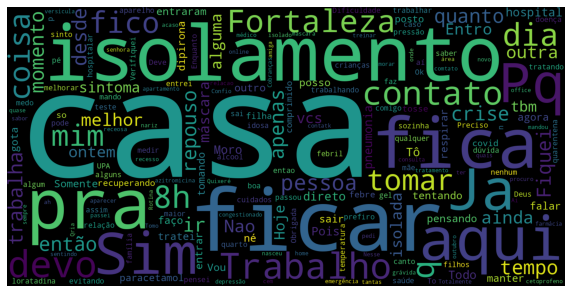





Total of sentences is: 95 for the label: 91


['Somente isso mesmo.' 'Isso' 'Isso vai resolver?' 'So isso mesmo'
 'Vou Fazer Isso' 'Isso mesmo' 'Tenho feito isso' 'Isso está estranho'
 'Pq sinto isso' 'Isso é ruim' 'Já estou fazendo isso'
 'Me preocupa pois isso pode agravar meus pulmões' 'Ol farei isso'
 'Essas doenças tbm podem ocasionar isso?' 'So isso abracao'
 'Somente isso.' 'Vou fazer isso' 'Estamos fazendo isso' 'É isso'
 'to tentando fazer isso']


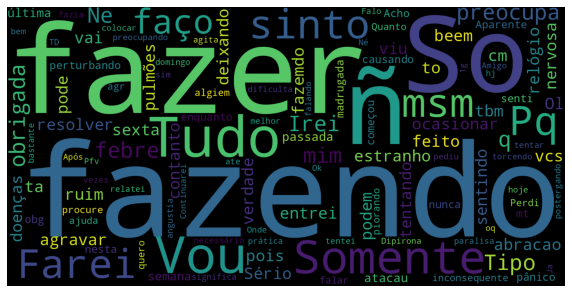





Total of sentences is: 475 for the label: 92


['Obrigada assim mesmo por a atenção e Jesus te lave com o sangue do cordeiro e te cubra de saúde'
 'Durante esse período de febre tomei Dipirona monoidratada, porém a febre vai e volta.'
 'Falta de apetite perda do alfato labios e boca seca boca amarga'
 'Da vontade de tosse e eu respiro pela boca pra voltar a respirar normal'
 'E a falta de ar??'
 'Bom eu sou portadora de lúpus e a mais ou menos 8 dias eu gripei e ainda estou. Sinto dores de cabeça  e dor na parte de trás próximo a nuca. Corpo mole uma moleza no corpo'
 'E estou muito preocupada de ter pego esse vírus'
 'Tomei Dipirona de 1g e  passou'
 'Estou sintomas de muita tosse e secreção esta com 5 dias'
 'falta de ar, coriza, falta de olfato e paladar e cansaço no peito'
 'me sinto cansada e fico com um pouco de falta de ar'
 'E de madrugada, ele começou a ir pro banheiro'
 'O nosso sistema de saúde e precária' 'sim e pouco de moleza no corpo.'
 'Falta de olfato e paladar'
 '

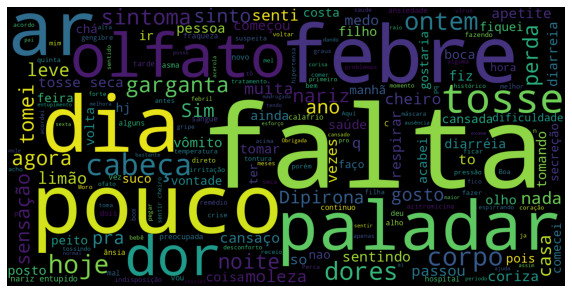





Total of sentences is: 178 for the label: 93


['Posso retomar o uso do Alektos? Me sinto bem quando uso'
 'Qual o nome do médico??' 'Queria q fosse gripe'
 'Qual hospital posso ir ?' 'Tenho q acompanhar por 48hr é isso?'
 'Posso continuar tomando o flamador cetoprofeno?'
 'Tomei o antiflamatorio 19:15 qual horário posso vir a tomar a Dipirona?'
 'Tem uma upa aqui ao Lado! Abrirá?' 'Ok esse é um antialergico?'
 'Devo levar ela no médico?' 'Sabe dizer qual hospital ele vá?'
 'Então Só devo me preocupar se tiver febre alta?'
 'Tomar algum medicamento?' 'Desde já?' 'Hoje estou me sentindo melhor'
 'posso procurar fazer o teste particular? se der positivo?'
 'Devo tomar algum remédio?' 'Qual delas?'
 'Qual quer coisa posso voltar a falar com vc?'
 'Caso precise qual hospital devo ir?']


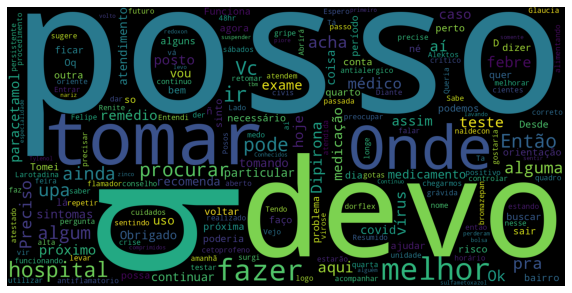





Total of sentences is: 486 for the label: 94


['O coração acelerado' 'O que  incomoda até o momento é  só a tosse'
 'Me passa o nomes dos laboratórios'
 'Qual medicamento pois o aliviar a garganta'
 'Mais devagar. O coração está sem alteração.'
 'naUPA o atendimento péssimo o povo chá que é dono ainda. passa anoite dormindo'
 'Queria fazer o teste' 'Posso esta utilizando o aerossol para o cansado'
 'Passado pelo o médico'
 'Mais nesse caso terei q ir a alguma unidade para o atestado'
 'Ele foi na UPA hoje e o médico disse que era virose. O mesmo passou dois medicamentos'
 'Mas ainda não voltou o paladar, o olfato' 'O cansaço continua'
 'Respiracao mais rápida  aue o normal' 'Doe um pouco o estômago'
 'Sinto tbm um pouco o paladar amargo' 'O medo me cerca'
 'O único vício é o cigarro, infelizmente'
 '5 dias mais o meu marido teve o diagnóstico positivo pra covid'
 'Moca como faz o teste e onde?']


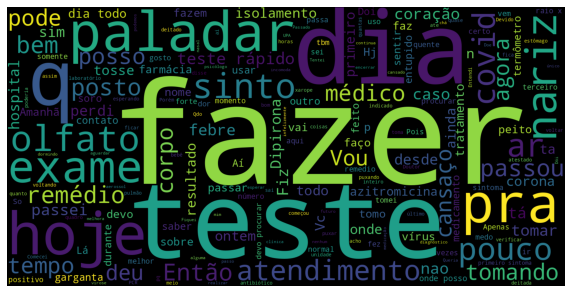





Total of sentences is: 873 for the label: 95


['Elas têm máscaras , falamos, mas aqui não tem os cuidados das autoridades de está colocando eles pra casa'
 'Triste, tenho medo de perder todos eles!'
 'Essa semana vou passar 15 dias sem ver minha filha, mandei ela é meu genrro ficarem em casa porque o cunhado dela está com todos sintomas de covid'
 'Ela ainda hoje leva os outros irmãos para os médicos. Ela acha que todos nós iremos ter que morrer ou de uma coisa ou de outra! Ela era da saúde'
 'O problema é encontrar um posto de Saúde funcionando'
 'Gostaria de saber qual remédio melhor pra tomar com esses sintomas'
 'Não passa de 37' 'Não é bem uma dor de garganta'
 'Não. Aparentemente apenas um quadro de febre'
 'Não sinto gosto de alimentos' 'Desde de quando começou essa pandemia'
 'Uma pontada com um pouco de ardência. Piora quando respiro, fica mais forte'
 'Só tenho vontade de tossir quando puxo o ar'
 'sim, mas há um grande risco de contaminação certo'
 'ela tava tossindo um

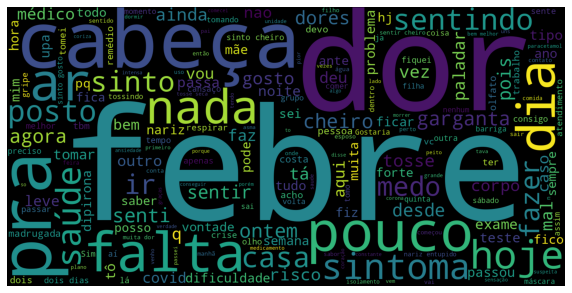





Total of sentences is: 157 for the label: 96


['As vezes embassada' 'Obrigada pelas as orientações' 'To preocupada'
 'As vezes tosse' 'E me sinto fraca as vezes tonta'
 'Receitou ;soro fisiológico,  paracetamol, e loratadina' 'Superior'
 'As veses' 'Agradeço as informações' 'Sim. Estava, 37, 5 ontem a noite.'
 'Sinto febre,tosse as vezes' 'So soro' 'Obrigada, novamente.' 'Olá,'
 'Enalapril 20mg , hidroclorotiazida 25mg' 'Náuseas, confusão mental'
 'As 13h' 'Dipirona , floratil, loratadina e soro' 'Sim, mantendo.'
 'Diarreia mole normal']


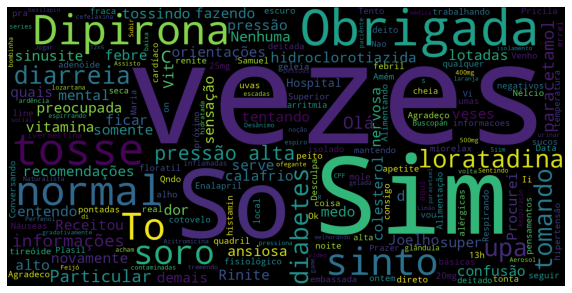





Total of sentences is: 866 for the label: 97


['Estou com idosos correndo risco de se contaminar'
 'Boa tarde! Tenho uma idosa de 84 anos e vivi na rua ,na mesma casa tem mais 2 idosos e o restante são idosos que vão passear lá  Idosos que moram na casa são 3  Uma de 89,outra de 84 e a mais nova de 74. O marido da idosa de 89 tem 80 e está vindo de quixeramobim pra vela não usa máscara , a outra que vem passear também tem 75 também não segue os cuidados. Já falei, levei máscara , a idosa que sai direto de casa tem o hábito de abraçar , beijar e dá a mão pra todo mundo! Ela é lúcida mas às vezes tem algum momento de demência , rir de tudo e acha que o que tá acontecendo é besteira  Elas vivem só , não querem'
 'Como assim doutora, cuidar de sí ?'
 'Perdi um primo 46 anos Rompimento da aorta coronária , tento ser forte pois a esposa e o menino estão precisando de ajuda psicológica'
 'Sou técnica de enfermagem  Aguardando a um ano aposentadoria'
 'Se precisar financeiramente sim! Mas

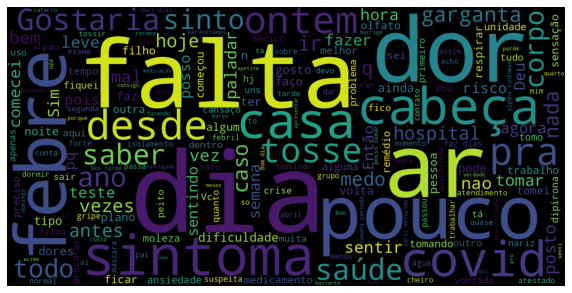





Total of sentences is: 204 for the label: 98


['Oq eu faço?' 'Como eu faço?'
 'ok, me ajudou bastante e eu retornarei, obrigada'
 'Eu estou com dificuldade para respirar' 'Se for a upa eu sei onde fica'
 'Eu posso morrer?' 'Eu moro em Pedras...' 'Se eu tiver febre a noite?'
 'Bem, eu tenho uma dúvida' 'Sim, eu estou em casa'
 'Eu agradeço a atenção' 'Eu trabalho  em uma loja no Drive thru.'
 'Deixa eu esplicar uma coisa. eu sou filha do paciente'
 'eu tomei loratadina e pasei rinosoro so'
 'eu estou tomando dipirona e benegripe'
 'Me corrija se eu estiver errada.'
 'Eu estou assintomática, mas.com medo. Devemos continuar em.isolamento tbm'
 'Eu durmo bem gracas a Deus' 'Alguns dias e eu estava gripada.'
 'Dor no peito quando falo ao tussir qualquer coisa q eu me esforce']


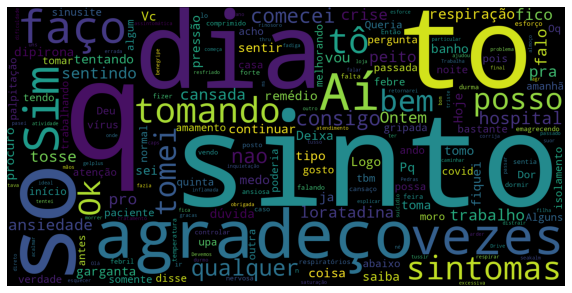

In [4]:
pipeline.visualize_word_clouds()

In [4]:
dict_intents = {
     0: 'others', #mixed
     1: 'others', #mixed
     2: 'others', #mixed
     3: 'others', #mixed
     4: 'greeting',
     5: 'request_inform',
     6: 'request_inform',
     7: 'others', #negative
     8: 'greeting',
     9: 'others', #mixed
    10: 'inform_medicine',
    11: 'others', #inform
    12: 'greeting', #few_sentences
    13: 'inform_symptoms',
    14: 'others', #mixed
    15: 'inform_symptoms',
    16: 'others', #inform #negative
    17: 'inform_symptoms',
    #18: '?', #empty
    19: 'request_inform',
    20: 'others', #mixed
    21: 'inform_symptoms',
    #22: '?', #empty
    23: 'others', #mixed
    24: 'others', #mixed
    25: 'greeting',
    26: 'inform_symptoms',
    27: 'inform_medicine',
    28: 'others', #inform #positive
    29: 'inform_medicine',
    30: 'inform_symptoms',
    31: 'others', #mixed
    32: 'inform_symptoms',
    33: 'inform_symptoms',
    34: 'others', #mixed
    35: 'inform_symptoms',
    36: 'inform_symptoms',
    37: 'inform_symptoms',
    38: 'inform_symptoms',
    39: 'inform_symptoms',
    40: 'inform_medicine',
    41: 'request_inform',
    42: 'inform_symptoms',
    43: 'others', #mixed
    44: 'inform_medicine',
    45: 'greeting',
    46: 'inform_symptoms',
    47: 'inform_symptoms',
    48: 'others', #mixed
    49: 'inform_symptoms',
    50: 'greeting',
    51: 'inform_symptoms',
    52: 'greeting',
    53: 'inform_symptoms',
    54: 'inform_symptoms',
    55: 'greeting',
    56: 'inform_symptoms',
    57: 'inform_symptoms',
    58: 'inform_symptoms',
    59: 'others', #mixed #few_sentences
    60: 'greeting',
    61: 'greeting',
    62: 'greeting',
    63: 'inform_symptoms',
    64: 'others', #mixed
    65: 'others', #mixed
    66: 'others', #mixed
    67: 'greeting',
    68: 'others', #address
    69: 'others', #address
    70: 'others', #unknown
    71: 'others', #mixed
    72: 'others', #mixed
    73: 'inform_symptoms',
    74: 'others', #mixed
    75: 'others', #mixed
    76: 'others', #mixed
    77: 'others', #mixed #age
    78: 'others', #mixed #general
    79: 'others', #mixed
    80: 'inform_symptoms',
    81: 'inform_symptoms',
    82: 'greeting',
    83: 'others', #mixed
    84: 'greeting',
    85: 'inform_symptoms',
    86: 'inform_symptoms',
    87: 'others', #mixed #general
    88: 'inform_symptoms',
    89: 'inform_symptoms',
    90: 'others', #general
    91: 'others', #general
    92: 'inform_symptoms',
    93: 'request_inform',
    94: 'inform_symptoms',
    95: 'inform_symptoms',
    96: 'others', #mixed
    97: 'inform_symptoms',
    98: 'request_inform',
}

In [5]:
pipeline.annotate_data(dict_intents)

applying map intents.....
saving data at: /home/valmir/dev/python/intent_classifier/data/output/patient/k100/glove/annotated_sentences.csv
saving data at: /home/valmir/dev/python/intent_classifier/data/output/patient/without_others_intent/k100/glove/annotated_sentences.csv
Describing data...
The total of sentences is: 26754
others, has 37 clusters, and 8999 sentences
greeting, has 14 clusters, and 1878 sentences
request_inform, has 6 clusters, and 981 sentences
inform_medicine, has 5 clusters, and 676 sentences
inform_symptoms, has 35 clusters, and 14220 sentences


In [6]:
pipeline.annotate_data_without_outliers(sub_folder_k='k100_without_outliers/', dict_intents=dict_intents)

applying map intents.....
saving data at: /home/valmir/dev/python/intent_classifier/data/output/patient/k100_without_outliers/glove/annotated_sentences.csv
saving data at: /home/valmir/dev/python/intent_classifier/data/output/patient/without_others_intent/k100_without_outliers/glove/annotated_sentences.csv
Describing data...
The total of sentences is: 25141
others, has 37 clusters, and 7811 sentences
greeting, has 14 clusters, and 1822 sentences
request_inform, has 6 clusters, and 954 sentences
inform_medicine, has 5 clusters, and 659 sentences
inform_symptoms, has 35 clusters, and 13895 sentences


In [7]:
pipeline.annotate_data_without_sentences_higher_than_median(sub_folder_k='k100_without_sentences_higher_than_median/', dict_intents=dict_intents)

applying map intents.....
saving data at: /home/valmir/dev/python/intent_classifier/data/output/patient/k100_without_sentences_higher_than_median/glove/annotated_sentences.csv
saving data at: /home/valmir/dev/python/intent_classifier/data/output/patient/without_others_intent/k100_without_sentences_higher_than_median/glove/annotated_sentences.csv
Describing data...
The total of sentences is: 12933
others, has 37 clusters, and 4033 sentences
greeting, has 14 clusters, and 948 sentences
request_inform, has 6 clusters, and 492 sentences
inform_medicine, has 5 clusters, and 340 sentences
inform_symptoms, has 35 clusters, and 7120 sentences
